# 25 Daten, Labels und Messlatte

Teil 6: Lernende Modelle

**Worum es geht**
- Bevor ein Modell lernen kann, muss feststehen, was es erkennen soll und woran man einen Fehler in den Stundenwerten überhaupt sieht.
- Das Notebook baut die Datenbasis für die Notebooks 26 bis 29: Stundenwerte mit Außentemperatur, ein Label (Zielmerkmal) je Fehlerart aus den Begehungen und Kennzahlen je Zähler.
- Dazu zwei Fragen vorab, deren Antworten die späteren Modelle bestimmen:
  - Wie sieht ein Fehler in den Daten aus? Dafür je Fehlerart eine Beispielstation vor und nach der Begehung (Abschnitt 7).
  - Wie gut trennt eine einzige, vorher festgelegte Kennzahl je Fehlerart? Das ist die Messlatte, die jedes spätere Modell schlagen muss (Abschnitt 9).
- Wichtigste Regel: Ein Modell, das Fehler erkennen soll, darf nur sehen, was vor der Begehung gemessen wurde. Danach ist der Fehler behoben.
- Stichtag ist der 1. September 2024. Davor lagen nur wenige Begehungen; bei diesen Zählern endet der Blick am Tag ihrer Begehung.

**Daten**
- liest: `data/processed/real_meters/<Zähler>.csv` und `hast_features.csv` (Anschlusswert) aus Notebook 00, Außentemperatur DWD Kitzingen, Begehungsprotokoll
- schreibt: `data/processed/modell_stunden.parquet`, `modell_kennzahlen.csv`, `modell_labels.csv`, Abbildungen nach `docs/assets/modelle/`
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/weather.py` (Wetter), `src/inspections.py` (Kästchen der Begehungen), `src/befundcodes.py` (Freitext-Befunde, siehe Notebook 14), `src/load_begehungen.py` (Zuordnung Begehung zu Zählernummer inkl. Zählerwechsel, siehe Notebook 02)
- Tests in `tests/test_befundcodes.py`

| Abschnitt | Inhalt |
|---|---|
| 1 | Wie es zu diesen Notebooks kam |
| 2 bis 5 | Stundenreihen, Außentemperatur, vollständige Tage |
| 6 | Labels aus den Begehungen |
| 7 | Wie sieht ein Fehler in den Daten aus? |
| 8 | Kennzahlen vor der Begehung |
| 9 | Messlatte: eine Kennzahl je Fehlerart |
| 10 | Ergebnis speichern |

## 1 Wie es zu diesen Notebooks kam

- Die Notebooks 25 bis 30 sind nicht der erste Versuch, Fehler an den Hausstationen (HAST) zu finden.
- Jeder frühere Versuch hat etwas gezeigt, meistens, warum er allein nicht reicht.

| Versuch | wo | Ergebnis | was daraus folgte |
|---|---|---|---|
| Regeln mit festen Schwellen (5 Fehlerfamilien) | `src/fault_detection.py` | synthetische Daten 100 %, echte Daten viel zu breit | Schwellen lassen sich nicht übertragen, es braucht echte Labels |
| Klassifikator „Maßnahme ja/nein“ | `src/ml_classifier.py` | Label trifft auf 40 von 49 Stationen zu, schlägt die Baseline nicht | Label zu grob, hier deshalb ein Label je Fehlerart |
| K-Means auf Stationsmerkmalen | [`07`](../3_clustering/07_stationscluster.ipynb), [`09`](../3_clustering/09_clustervalidierung.ipynb), [`10`](../3_clustering/10_tagescluster.ipynb) | keine natürlichen Gruppen (Silhouette unter 0,25) | K-Means nur mit klarem Zweck, siehe [`26`](26_einstufung.ipynb) |
| Anomalie-Scores: Isolation Forest, LOF, PCA, K-Means-Distanz | Gesamtpipeline (August, nicht im Abgabestand) | gegen „Maßnahme ja/nein“ AUC 0,49 bis 0,53, also Zufall; von 10 Ereignissen höchstens 2 gefunden | „auffällig“ ist nicht „Fehler“; das Modell muss eine bestimmte Fehlerart lernen |
| Kennlinienmonitor | [`13`](../4_stationsbilder/13_kennlinienmonitor.ipynb), [`14`](../4_stationsbilder/14_befunde.ipynb) | etwa 1,3-fach über Zufall; mechanische Eingriffe 10 von 19 | das Messsignal lohnt sich, wenn man weiß, wonach man sucht |
| Normalverhaltensmodell | [`18`](../5_monitoring/18_normalverhalten.ipynb) | Alarme treffen Begehungen zu 70 % gegen 53 % ohne Begehung | guter Wächter für den Winter, Vergleich in [`30`](30_waechtervergleich.ipynb) |
| Regeln und Kennzahlen je Fehlerart | lokale Vorarbeit | Ventil mit Sommernacht-Regel AUC 0,91, Dämmung mit keiner Regel über 0,5 | Regeln finden nur Bekanntes und nur im Sommer, siehe [`27`](27_lstm.ipynb) |

- AUC = Fläche unter der ROC-Kurve; 0,5 ist Zufall, 1 ist perfekt.
- Lehre: Ohne ein Label je Fehlerart lernt kein Modell etwas Brauchbares. Mit nur 53 begangenen Stationen lernt ein großes Modell die Fälle auswendig.
- Ausweg in den Notebooks 27 und 28: Ein LSTM (neuronales Netz für Zeitreihen) lernt zuerst ohne Labels, wie sich die Stationen verhalten. Erst danach kommen die Labels dazu.

| Notebook | Frage |
|---|---|
| 27 (dieses) | Welche Daten und welche Labels? |
| [`26`](26_einstufung.ipynb) | Läuft eine Station im Optimum oder schlechter? |
| [`27`](27_lstm.ipynb) | Welche Station hat welchen Fehler? (LSTM) |
| [`28`](28_prognose_lstm.ipynb) | Wo ändert sich gerade etwas? (Prognose-LSTM) |
| [`29`](29_xgboost.ipynb) | Bringen XGBoost und Co. mehr? Klassen der Folie 5 für jede Station |
| [`30`](30_waechtervergleich.ipynb) | Wie schlägt sich der LSTM-Wächter gegen das Normalverhaltensmodell? |

## 2 Setup

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message=".*Data Validation extension.*")

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import befundcodes, inspections, load_begehungen
from src.load_data import load_inspections
from src.weather import load_outdoor_temperature

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

PROCESSED = ROOT / "data" / "processed"
METER_DIR = PROCESSED / "real_meters"

STICHTAG = pd.Timestamp("2024-09-01")
WINTER = (pd.Timestamp("2023-10-01"), pd.Timestamp("2024-04-01"))   #Heizperiode vor den Begehungen
SOMMER = (pd.Timestamp("2024-06-01"), pd.Timestamp("2024-09-01"))   #Sommer vor den Begehungen
print(f"{len(list(METER_DIR.glob('*.csv')))} Zählerreihen aus Notebook 00")

93 Zählerreihen aus Notebook 00


- Sucht die Projektwurzel und macht `src/` importierbar.
- Legt drei Zeiträume fest, die in allen Modell-Notebooks gleich sind: den Stichtag, den Winter 2023/24 und den Sommer 2024. Winter und Sommer liegen vor den Begehungen.

## 3 Die Stundenreihen aus Notebook 00

- Notebook 00 hat je Zähler eine Datei geschrieben: Exporte zusammengeführt, auf volle Stunden gerundet, unmögliche Werte entfernt, lückenloses Stundenraster.
- Hier werden alle 93 Dateien zu einer Tabelle zusammengelegt: eine Zeile je Zähler und Stunde.

In [2]:
SPALTEN = {
    "Timestamp": "timestamp",
    "Flow temperature (°C)": "vorlauf",
    "Return temperature (°C)": "ruecklauf",
    "Temperature difference (°C)": "spreizung",
    "Volume flow (l/h)": "durchfluss",
    "Power (kW)": "leistung",
}
teile = []
for pfad in sorted(METER_DIR.glob("*.csv")):
    df = pd.read_csv(pfad, usecols=list(SPALTEN), parse_dates=["Timestamp"]).rename(columns=SPALTEN)
    df.insert(0, "zaehler", int(pfad.stem))
    teile.append(df)
stunden = pd.concat(teile, ignore_index=True)

print(f"{len(stunden):,} Stundenzeilen von {stunden['zaehler'].nunique()} Zählern")
print(f"Zeitraum: {stunden['timestamp'].min():%d.%m.%Y} bis {stunden['timestamp'].max():%d.%m.%Y}")
print(f"davon mit Messwert: {stunden['ruecklauf'].notna().mean():.0%}")
stunden.head()

2,128,400 Stundenzeilen von 93 Zählern
Zeitraum: 01.11.2021 bis 20.07.2026
davon mit Messwert: 80%


,zaehler,timestamp,durchfluss,leistung,spreizung,vorlauf,ruecklauf
0,53198226,2021-11-01 23:00:00,0.0,0.0,11.5,66.6,55.0
1,53198226,2021-11-02 00:00:00,NaN,NaN,NaN,NaN,NaN
2,53198226,2021-11-02 01:00:00,NaN,NaN,NaN,NaN,NaN
3,53198226,2021-11-02 02:00:00,NaN,NaN,NaN,NaN,NaN
4,53198226,2021-11-02 03:00:00,NaN,NaN,NaN,NaN,NaN


- Liest jede Zählerdatei, behält die fünf Messgrößen und gibt ihnen kurze deutsche Namen.
- Die Zählernummer kommt aus dem Dateinamen und steht in der ersten Spalte.
- Die leeren Zeilen sind gewollt: Notebook 00 legt für jede Stunde eine Zeile an, auch für nicht gemessene. So gilt „eine Zeile = eine Stunde“.

### 3.1 Erst einmal anschauen

- Welche Spalten und Datentypen gibt es, wie viel fehlt?
- Liegen die Werte in einem physikalisch sinnvollen Bereich?

In [3]:
stunden.info()

<class 'pandas.DataFrame'>
RangeIndex: 2128400 entries, 0 to 2128399
Data columns (total 7 columns):
 #   Column      Dtype         
---  ------      -----         
 0   zaehler     int64         
 1   timestamp   datetime64[us]
 2   durchfluss  float64       
 3   leistung    float64       
 4   spreizung   float64       
 5   vorlauf     float64       
 6   ruecklauf   float64       
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 113.7 MB


In [4]:
uebersicht = stunden.drop(columns=["zaehler", "timestamp"]).describe().T
uebersicht["fehlend"] = stunden.drop(columns=["zaehler", "timestamp"]).isna().mean().round(3)
uebersicht.round(1)

,count,mean,std,min,25%,50%,75%,max,fehlend
durchfluss,1692110.0,327.7,1405.3,-999.0,0.0,53.0,186.0,26135.0,0.2
leistung,1690145.0,5.2,24.4,-180.3,0.0,0.7,3.5,747.7,0.2
spreizung,1678654.0,16.7,13.6,-35.4,4.6,14.7,27.9,60.7,0.2
vorlauf,1692166.0,63.0,15.5,9.5,56.3,69.4,73.9,91.5,0.2
ruecklauf,1692166.0,46.2,15.3,8.6,33.0,45.7,57.1,89.0,0.2


- Sieben Spalten: Zählernummer, Zeitstempel und fünf Messgrößen. Zusammen 2,1 Mio. Zeilen, rund 114 MB im Speicher.
- Rund ein Fünftel jeder Messgröße fehlt (Spalte `fehlend`: 0,2). Das sind die Lücken aus Notebook 00 (dort: 80 % der Stunden gemessen).
- Die typischen Werte sind plausibel:
  - Vorlauf in der mittleren Hälfte der Stunden zwischen 56 und 74 °C, Rücklauf zwischen 33 und 57 °C.
  - Durchfluss im Median 53 l/h; einzelne große Abnehmer kommen auf über 20.000 l/h und über 700 kW.
- Es gibt unmögliche Ausreißer nach unten: Durchfluss bis −999 l/h, Leistung bis −180 kW. Notebook 00 lässt Werte zwischen −1000 und 50.000 l/h stehen. Für die Kennzahlen ist das unkritisch, sie nutzen nur Stunden mit Durchfluss über 1 bzw. 5 l/h. Das LSTM sieht diese Werte, sie sind aber sehr selten (25-%-Quantil bei 0).
- Spreizung = Vorlauf minus Rücklauf. Sie kann negativ sein, wenn ohne Durchfluss das stehende Wasser auskühlt. Spreizungs-Kennzahlen nutzen deshalb nur Stunden, in denen Wasser fließt.

In [5]:
BEISPIEL = stunden.groupby("zaehler")["ruecklauf"].count().idxmax()
beispiel = stunden[(stunden["zaehler"] == BEISPIEL) & (stunden["timestamp"] >= "2024-01-15")].head(24)
print(f"Ein Wintertag des Zählers {BEISPIEL} (der mit den meisten Messstunden):")
beispiel

Ein Wintertag des Zählers 68956347 (der mit den meisten Messstunden):


,zaehler,timestamp,durchfluss,leistung,spreizung,vorlauf,ruecklauf
318040,68956347,2024-01-15 00:00:00,162.0,5.949,31.8,73.2,41.4
318041,68956347,2024-01-15 01:00:00,131.0,5.700,37.7,74.2,36.5
318042,68956347,2024-01-15 02:00:00,153.0,5.500,31.2,74.8,43.6
318043,68956347,2024-01-15 03:00:00,166.0,6.831,35.6,75.4,39.7
318044,68956347,2024-01-15 04:00:00,138.0,5.636,35.4,75.4,40.0
318045,68956347,2024-01-15 05:00:00,180.0,6.621,31.9,74.1,42.2
318046,68956347,2024-01-15 06:00:00,216.0,8.239,32.9,74.1,41.1
318047,68956347,2024-01-15 07:00:00,454.0,10.810,20.7,74.5,53.7
318048,68956347,2024-01-15 08:00:00,476.0,6.712,12.3,76.0,63.7
318049,68956347,2024-01-15 09:00:00,462.0,4.822,9.1,73.8,64.6


- Der Vorlauf kommt vom Netz und schwankt wenig.
- Durchfluss und Leistung gehen mit dem Wärmebedarf hoch und runter.
- Die Spreizung zeigt, wie viel Wärme die Station dem Wasser entzieht.
- Leistung ≈ 1,16 · Durchfluss [m³/h] · Spreizung: Die drei Größen hängen physikalisch zusammen.

## 4 Außentemperatur dazu

- Wie viel eine Station heizt, hängt vor allem am Wetter. Ein Modell ohne Wetter hält jeden kalten Tag für auffällig.
- Die Außentemperatur kommt aus `src/weather.py` (DWD-Station Kitzingen, auf dieselbe Lokalzeit gebracht wie die Zählerexporte).

Wetter: 41,312 Stunden, Spalten ['timestamp', 't_out', 'interpolated']
count    41303.0
mean        11.2
std          8.5
min        -13.8
25%          4.7
50%         10.5
75%         17.1
max         40.4
davon linear aufgefüllt (Lücken bis 6 h): 7 Stunden

Außentemperatur fehlt nach dem Anhängen in 0.03% der Stunden


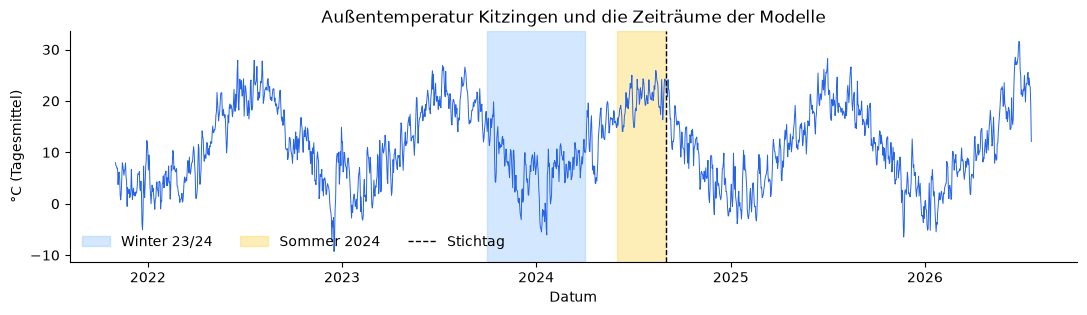

In [6]:
wetter = load_outdoor_temperature(stunden["timestamp"].min(), stunden["timestamp"].max())
print(f"Wetter: {wetter.shape[0]:,} Stunden, Spalten {list(wetter.columns)}")
print(wetter["t_out"].describe().round(1).to_string())
print(f"davon linear aufgefüllt (Lücken bis 6 h): {wetter['interpolated'].sum()} Stunden")
wetter = wetter.rename(columns={"t_out": "aussen"})[["timestamp", "aussen"]]
stunden = stunden.merge(wetter, on="timestamp", how="left")
print(f"\nAußentemperatur fehlt nach dem Anhängen in {stunden['aussen'].isna().mean():.2%} der Stunden")

tagesmittel = wetter.set_index("timestamp")["aussen"].resample("D").mean()
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(tagesmittel.index, tagesmittel, lw=0.7, color="#2563EB")
for (von, bis), farbe, name in ((WINTER, "#93C5FD", "Winter 23/24"), (SOMMER, "#FCD34D", "Sommer 2024")):
    ax.axvspan(von, bis, color=farbe, alpha=0.4, label=name)
ax.axvline(STICHTAG, color="black", ls="--", lw=1, label="Stichtag")
ax.set_xlabel("Datum")
ax.set_ylabel("°C (Tagesmittel)")
ax.set_title("Außentemperatur Kitzingen und die Zeiträume der Modelle")
ax.legend(frameon=False, ncol=3, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- Holt die stündliche Außentemperatur (beim ersten Lauf von DWD Open Data, danach aus dem Cache in `data/raw/weather/`) und hängt sie per Zeitstempel an.
- Die Grafik zeigt die Zeiträume, die die Modelle später nutzen. Alles links der gestrichelten Linie liegt vor den Begehungen.

## 5 Wie viele brauchbare Tage hat jeder Zähler?

- Die LSTM-Modelle in Notebook 27 und 28 lesen ganze Tage, also 24 Stunden am Stück.
- Ein Tag zählt nur, wenn alle 24 Stunden aller Größen gemessen sind.
- Lücken werden nicht gefüllt: Das Netz würde sonst erfundene Stunden lernen.

In [7]:
KANAELE = ["vorlauf", "ruecklauf", "spreizung", "durchfluss", "leistung", "aussen"]
stunden["tag"] = stunden["timestamp"].dt.floor("D")
stunden["vollstaendig"] = stunden[KANAELE].notna().all(axis=1)
tage = stunden.groupby(["zaehler", "tag"])["vollstaendig"].sum().rename("stunden").reset_index()
tage["voll"] = tage["stunden"] == 24

ZEITRAEUME = {
    "Winter 22/23": ("2022-10-01", "2023-04-01"),
    "Winter 23/24": ("2023-10-01", "2024-04-01"),
    "Sommer 2024": ("2024-06-01", "2024-09-01"),
    "ab Stichtag": ("2024-09-01", "2030-01-01"),
}
volle_tage = pd.DataFrame({
    name: tage[(tage["tag"] >= von) & (tage["tag"] < bis) & tage["voll"]].groupby("zaehler").size()
    for name, (von, bis) in ZEITRAEUME.items()
}).reindex(stunden["zaehler"].unique()).fillna(0).astype(int)
volle_tage.index.name = "zaehler"
print(f"Vollständige Tage insgesamt: {tage['voll'].sum():,} von {len(tage):,}")
volle_tage.describe().round(0)

Vollständige Tage insgesamt: 67,840 von 88,792


,Winter 22/23,Winter 23/24,Sommer 2024,ab Stichtag
count,93.0,93.0,93.0,93.0
mean,60.0,156.0,78.0,294.0
std,68.0,47.0,28.0,127.0
min,0.0,0.0,0.0,0.0
25%,0.0,143.0,89.0,298.0
50%,0.0,180.0,90.0,308.0
75%,137.0,180.0,90.0,309.0
max,138.0,181.0,90.0,680.0


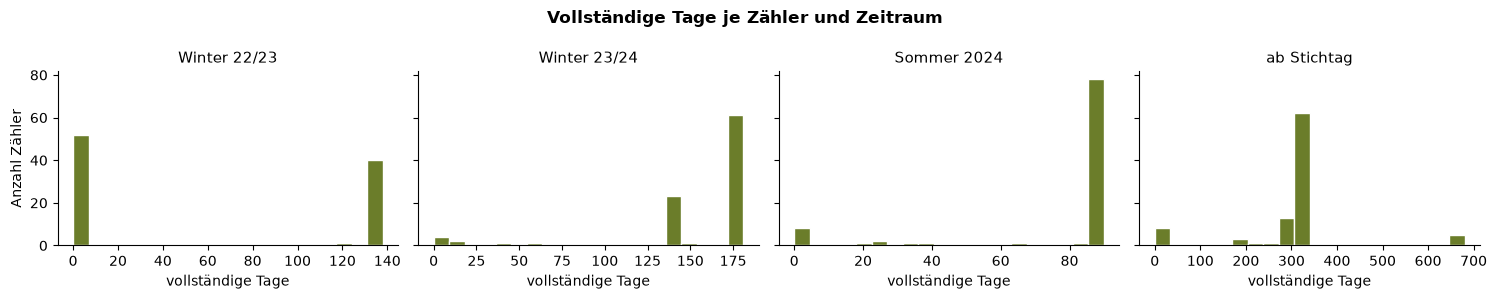

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, name in zip(axes, volle_tage.columns):
    ax.hist(volle_tage[name], bins=20, color="#6B7D2A", edgecolor="white")
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("vollständige Tage")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Anzahl Zähler")
fig.suptitle("Vollständige Tage je Zähler und Zeitraum", fontweight="bold")
fig.tight_layout()
plt.show()

- Je Zähler und Tag wird gezählt, wie viele Stunden alle sechs Größen haben. Nur Tage mit 24 solchen Stunden sind „voll“.
- Die Tabelle zählt die vollen Tage je Zeitraum. Ein Winter hat 182 Tage, der Sommer 92.
- Der Tag der Zeitumstellung im März hat nur 23 Stunden und fällt deshalb immer heraus. Das kostet einen Tag im Jahr.

- Von knapp 89.000 Zähler-Tagen sind knapp 68.000 vollständig. Die übrigen haben Lücken, oft nur einzelne Stunden.
- Winter 23/24 und Sommer 2024 sind gut abgedeckt: im Median 180 von 182 Wintertagen und 90 von 92 Sommertagen. Auf diesen beiden Zeiträumen bauen die Modelle auf.
- Winter 22/23 hat nur knapp die Hälfte: 41 Zähler haben dort mindestens 60 volle Tage, der Rest kam erst 2023 dazu (zwei Rollout-Wellen, siehe Notebook 00). Vergleiche über zwei Winter (Notebook 27) gehen deshalb nur mit diesen 41 Zählern.
- Nach dem Stichtag hat ein typischer Zähler gut 300 volle Tage. Das reicht, um in Notebook 28 die Zeit nach den Begehungen zu beobachten.

## 6 Labels aus den Begehungen

- Was ein Modell erkennen soll, steht im Begehungsprotokoll (66 Begehungen).
- Quelle 1, Kästchen (`src/inspections.py`): Filter gereinigt, Durchfluss eingestellt, Leitungen gedämmt, Stellmotor bzw. Stellventil getauscht, Vertragsleistung alt/neu.
- Quelle 2, Freitext „Sonstiges“ (`src/befundcodes.py`): Viele Befunde stehen nur dort, etwa ein klemmendes Regelventil.
- Zuerst ein Blick darauf, wie die Kästchen ausgefüllt wurden. Das erklärt später, warum manche Fehlerarten nicht lernbar sind.

In [9]:
roh = load_inspections()
#Die Rohtabelle enthält Adressen. Deshalb nur Größe und Spaltennamen ansehen, keine Zeilen.
print(f"Begehungsprotokoll: {roh.shape[0]} Zeilen × {roh.shape[1]} Spalten")
print("Spalten (Auswahl):", [c.replace("\n", " ") for c in roh.columns[:12]], "...")

Begehungsprotokoll: 66 Zeilen × 134 Spalten
Spalten (Auswahl): ['Nr.', 'Datum', 'Straßenname', 'Hausnummer', 'Dauer (Uhrzeit)', 'Dauer (Uhrzeit)', 'Anlagen- konfiguration auf Seite 125', 'Station auf Seite 125', 'Zusatz- heizungen', 'Anzahl Personen', 'beheizte Wohnfläche', 'Inbetriebnahmejahr'] ...


- Lädt das Begehungsprotokoll (66 Begehungen, über 100 Spalten mit zweizeiligem Kopf).
- Gezeigt werden nur Größe und erste Spaltennamen. Die Zeilen enthalten Adressen und werden in keinem dieser Notebooks angezeigt.

In [10]:
KAESTCHEN = {
    "Filter gereinigt": "Filter\ngereinigt",
    "Durchfluss eingestellt": "Durchfluss neu\neingestellt",
    "Leitungen gedämmt": "Leitungen\nneu gedämmt",
    "Stellmotor getauscht": "Stellmotor\ngetauscht",
    "Stellventil getauscht": "Stellventil\ngetauscht",
}

def zustand(wert):
    w = str(wert).strip().lower()
    if w == "ja":
        return "ja"
    if w == "nein":
        return "ausdrücklich nein"
    return "leer"

ausfuellung = pd.DataFrame({name: roh[spalte].map(zustand).value_counts() for name, spalte in KAESTCHEN.items()}).T
ausfuellung = ausfuellung.reindex(columns=["ja", "ausdrücklich nein", "leer"]).fillna(0).astype(int)
ausfuellung

,ja,ausdrücklich nein,leer
Filter gereinigt,31,4,31
Durchfluss eingestellt,23,6,37
Leitungen gedämmt,23,8,35
Stellmotor getauscht,2,11,53
Stellventil getauscht,2,12,52


- Zählt je Kästchen, wie oft „ja“, wie oft ausdrücklich „nein“ und wie oft nichts eingetragen ist.

- Die Kästchen wurden fast nur ausgefüllt, wenn etwas gemacht wurde. Ein ausdrückliches „nein“ steht beim Filter 4-mal, beim Durchfluss 6-mal, bei der Dämmung 8-mal. In jeweils rund der Hälfte der Zeilen steht nichts.
- Für ein Modell heißt das: Die Gegenbeispiele („kein Filterproblem“) sind fast alle leere Kästchen. Ob dort wirklich nichts war, weiß niemand. Wer „leer“ als „nein“ liest, trifft eine Annahme.
- Stellmotor und Stellventil sind nur je 2-mal angekreuzt. Die meisten Ventilbefunde stehen im Freitext. Das Ventil-Label nimmt deshalb beide Quellen zusammen.

In [11]:
tidy = inspections.tidy_inspections()
zaehler_mit_reihe = set(stunden["zaehler"].unique())
kodiert = befundcodes.kodiere_begehungen(load_begehungen.begehungen_mit_zaehler(available=zaehler_mit_reihe))

#Beide Loader lesen dieselben 66 Zeilen in derselben Reihenfolge - das wird hier geprüft,
#bevor die Spalten nebeneinandergelegt werden.
assert len(tidy) == len(kodiert) and (tidy["address_norm"].values == kodiert["key"].values).all()

soll_alt = pd.to_numeric(kodiert["rw_soll_tag_alt"], errors="coerce")
soll_neu = pd.to_numeric(kodiert["rw_soll_tag_neu"], errors="coerce")
vertrag_bekannt = tidy["vertrag_alt_kw"].notna() & tidy["vertrag_neu_kw"].notna()

begehungen = pd.DataFrame({
    "zaehler": kodiert["meter"].astype(int),
    "datum": pd.to_datetime(kodiert["datum"], errors="coerce"),
    "ventil": tidy["stellventil_getauscht"] | tidy["stellmotor_getauscht"] | kodiert["ventil_stellantrieb"],
    "daemmung": tidy["daemmung_neu"] | kodiert["daemmung"],
    "filter": tidy["filter_gereinigt"],
    "durchfluss": tidy["durchfluss_neu"],
    "temperatur": soll_neu < soll_alt,
    "ueberdimensioniert": (tidy["vertrag_neu_kw"] < tidy["vertrag_alt_kw"]).astype(float).where(vertrag_bekannt),
    #Vertragsleistung, wie sie VOR der Begehung galt (für die Auslastung in Abschnitt 6)
    "vertrag_alt_kw": tidy["vertrag_alt_kw"],
    "vertrag_neu_kw": tidy["vertrag_neu_kw"],
    #Straße nur als Nummer: dient später dazu, ganze Straßen gemeinsam auszulassen
    "strasse_gruppe": pd.factorize(tidy["address_norm"].str.rsplit(" ", n=1).str[0])[0],
})
print(f"{len(begehungen)} Begehungen, {begehungen['zaehler'].nunique()} verschiedene Zähler, "
      f"davon mit Zeitreihe: {begehungen['zaehler'].isin(zaehler_mit_reihe).sum()} Begehungen")
begehungen.head()

66 Begehungen, 62 verschiedene Zähler, davon mit Zeitreihe: 59 Begehungen


,zaehler,datum,ventil,daemmung,filter,durchfluss,temperatur,ueberdimensioniert,vertrag_alt_kw,vertrag_neu_kw,strasse_gruppe
0,72167782,NaT,True,True,False,True,True,NaN,NaN,NaN,0
1,68956367,2025-09-12,False,False,True,False,True,0.0,8.0,8.0,0
2,68956348,2024-09-09,False,False,True,True,False,NaN,NaN,NaN,0
3,68956353,2024-09-23,False,True,False,True,True,0.0,8.0,8.0,1
4,80912195,2024-09-11,False,False,False,False,False,NaN,NaN,NaN,1


In [12]:
#Kurzer Blick auf die neue Tabelle: Datentypen und wie viele Werte je Spalte fehlen
werte = begehungen.drop(columns=["zaehler", "strasse_gruppe"]).select_dtypes(["bool", "number"])
pd.DataFrame({"Typ": begehungen.dtypes.astype(str), "fehlend": begehungen.isna().sum(),
              "Anteil ja / Mittelwert": werte.mean().round(2)})

,Typ,fehlend,Anteil ja / Mittelwert
daemmung,bool,0,0.39
datum,datetime64[us],8,NaN
durchfluss,bool,0,0.35
filter,bool,0,0.47
strasse_gruppe,int64,0,NaN
temperatur,bool,0,0.56
ueberdimensioniert,float64,22,0.20
ventil,bool,0,0.17
vertrag_alt_kw,float64,22,10.36
vertrag_neu_kw,float64,19,10.19


- `tidy_inspections()` liefert die Kästchen, `kodiere_begehungen()` die Freitext-Befunde samt Zählernummer. Bei Zählerwechsel wird der Zähler gewählt, für den es eine Zeitreihe gibt.
- Je Begehung entstehen sechs Labels:

| Label | ja, wenn … |
|---|---|
| `ventil` | Stellventil oder Stellmotor getauscht oder Ventilbefund im Freitext |
| `daemmung` | Leitungen gedämmt oder Dämmungsbefund im Freitext |
| `filter` | Filter gereinigt |
| `durchfluss` | Durchfluss neu eingestellt |
| `temperatur` | Rücklauf-Sollwert tagsüber gesenkt |
| `ueberdimensioniert` | Vertragsleistung neu kleiner als alt (leer, wenn nicht beide eingetragen) |

- Lesart „leer ist nein“: Ein leeres Kästchen zählt als „nein“. Das ist eine Annahme; die Tabelle oben zeigt, wie viel daran hängt.
- Zweite Tabelle: Die Kästchen-Labels sind immer gefüllt (wegen „leer ist nein“). Bei 8 Begehungen fehlt das Datum, bei 22 die Vertragsleistung; dort ist „überdimensioniert“ leer.
- Die Adresse dient nur dem Abgleich und wird nicht weitergegeben. Übrig bleibt eine Nummer je Straße.

In [13]:
LABELS = ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]
labels = begehungen.groupby("zaehler").agg(
    begehungen=("datum", "size"),
    erste_begehung=("datum", "min"),
    strasse_gruppe=("strasse_gruppe", "first"),
    vertrag_alt_kw=("vertrag_alt_kw", "first"),
    vertrag_neu_kw=("vertrag_neu_kw", "first"),
    **{name: (name, "max") for name in LABELS},
)
labels = labels[labels.index.isin(zaehler_mit_reihe)]
for name in LABELS[:-1]:
    labels[name] = labels[name].astype(bool)

basisraten = pd.DataFrame({
    "Fälle": labels[LABELS].sum().astype(int),
    "bekannt": labels[LABELS].notna().sum(),
})
basisraten["Anteil"] = (basisraten["Fälle"] / basisraten["bekannt"]).round(2)
print(f"{len(labels)} begangene Zähler mit Zeitreihe; {(labels['begehungen'] > 1).sum()} davon mehrfach begangen")
print(f"Begehungen vor dem Stichtag: {(labels['erste_begehung'] < STICHTAG).sum()}")
basisraten

56 begangene Zähler mit Zeitreihe; 3 davon mehrfach begangen
Begehungen vor dem Stichtag: 2


,Fälle,bekannt,Anteil
ventil,11,56,0.20
daemmung,23,56,0.41
filter,26,56,0.46
durchfluss,20,56,0.36
temperatur,36,56,0.64
ueberdimensioniert,9,37,0.24


- Fasst die Begehungen je Zähler zusammen. Bei zwei Begehungen gilt ein Befund, wenn er bei einer davon gefunden wurde.
- Die Tabelle zeigt die Basisraten: wie viele Fälle es je Fehlerart gibt. Ein Modell muss besser sein als blindes Raten mit genau diesem Anteil.

- 56 begangene Zähler haben eine Zeitreihe. Nur 2 davon wurden vor dem Stichtag begangen (August 2024), die meisten im September 2024.
- Ventil: 11 Fälle, also 20 %. Eine zufällige Liste von zehn Zählern enthielte im Mittel 2 Ventilfälle. Das ist die Messlatte für Precision@10 (Treffer unter den ersten zehn) in den folgenden Notebooks.
- Dämmung (23) und Durchfluss (20) liegen um 40 %, Filter (26) fast bei der Hälfte.
- Temperatur: Der Sollwert wurde bei knapp zwei Dritteln gesenkt. Das ist eher die Regel als ein Befund.
- Überdimensioniert: nur für 37 Zähler bekannt, weil die Vertragsleistung nicht überall alt und neu eingetragen ist. 9 davon wurden verkleinert.

## 7 Wie sieht ein Fehler in den Daten aus?

- Die Labels sagen, was bei der Begehung gemacht wurde. Ob man das vorher in den Stundenwerten sieht, ist offen.
- Deshalb zuerst einzelne Stationen ansehen, bei denen etwas gefunden wurde: wie sieht die Station vor und nach der Begehung aus?
- Ergebnis dieses Abschnitts ist, wonach die Kennzahlen in Abschnitt 8 und 9 suchen sollen.

In [14]:
lab = labels.reset_index()
befunde = ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]
BILDER = ROOT / "docs" / "assets" / "modelle"
BILDER.mkdir(parents=True, exist_ok=True)

- `lab` ist die Label-Tabelle aus Abschnitt 6 mit der Zählernummer als Spalte.
- Abbildungen, die auch in der Doku stehen, werden nach `docs/assets/modelle/` gespeichert.

### 7.1 Ventil an einem Beispiel

- 11 Stationen hatten einen Ventilbefund. Als Beispiel dient Zähler 68956351: Begehung am 09.09.2024, laut Protokoll wurde der Stellmotor getauscht.

In [15]:
df = pd.read_csv(METER_DIR / "68956351.csv", parse_dates=["Timestamp"])
print(len(df), "Zeilen")

32342 Zeilen


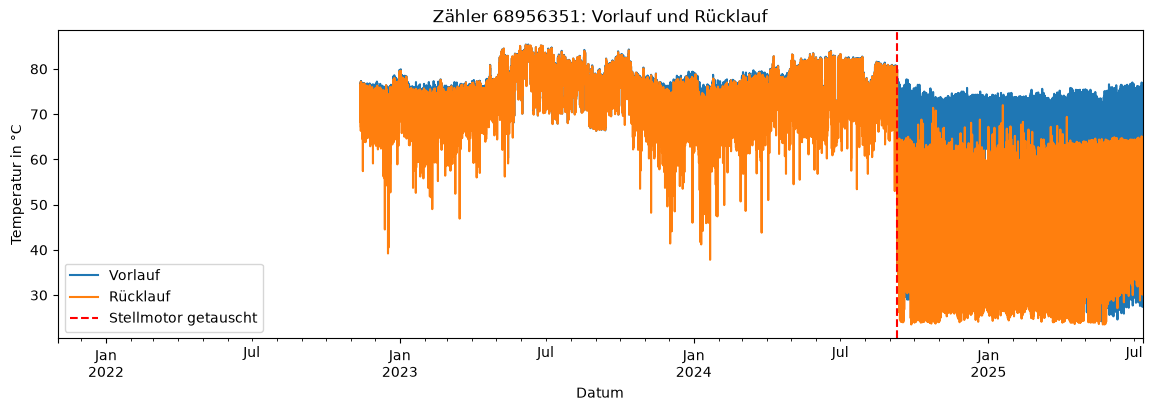

In [16]:
ax = df.plot(x = "Timestamp", y= ["Flow temperature (°C)", "Return temperature (°C)"], figsize= (14, 4))
ax.axvline(pd.Timestamp("2024-09-09"), color="red", linestyle="--")
ax.set_title("Zähler 68956351: Vorlauf und Rücklauf")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur in °C")
ax.legend(["Vorlauf", "Rücklauf", "Stellmotor getauscht"])

In [17]:
ax.figure.savefig(BILDER / "27_ventil_vorlauf_ruecklauf.png", bbox_inches="tight")

- Beim Tausch (rote Linie) fällt der Rücklauf von rund 75 °C auf unter 40 °C.
- Vorher war der Rücklauf fast so heiß wie der Vorlauf: Das Wasser ist durch die Station gelaufen, ohne Wärme abzugeben.

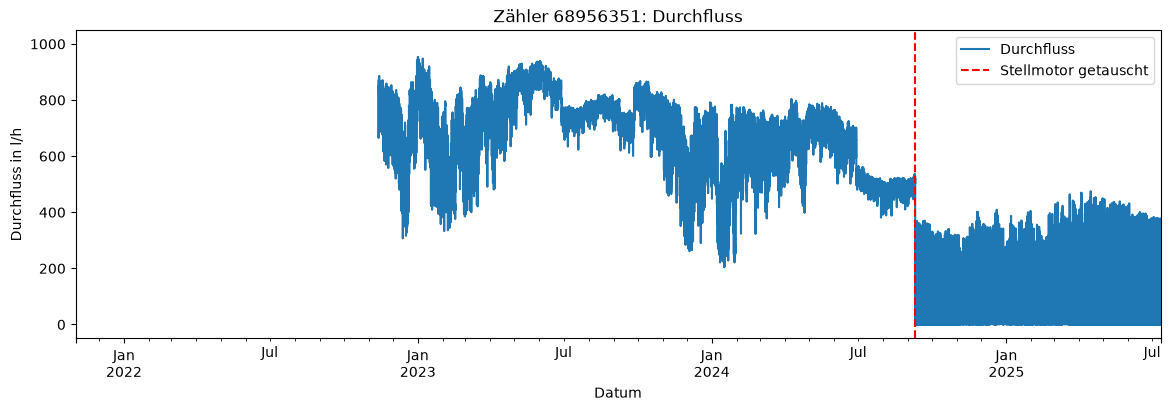

In [18]:
ax = df.plot(x= "Timestamp", y= "Volume flow (l/h)", figsize = (14, 4))
ax.axvline(pd.Timestamp("2024-09-09"), color="red", linestyle="--")
ax.set_title("Zähler 68956351: Durchfluss")
ax.set_xlabel("Datum")
ax.set_ylabel("Durchfluss in l/h")
ax.legend(["Durchfluss", "Stellmotor getauscht"])

- Nach dem Tausch fließt viel weniger Wasser: im Januar 2024 im Mittel 483 l/h, im Januar 2025 103 l/h.
- Das passt zur Physik: Wärme ≈ Durchfluss × Spreizung. Kühlt das Wasser stärker ab, reicht weniger Wasser für dieselbe Wärme.
- Daten nach dem 09.09.2024 dürfen deshalb nicht ins Modell. Sonst sieht es die reparierte Station, und die Diagnose wäre geschenkt (Leakage).

**Liegt es nur am Wetter?** Ein kalter Januar braucht mehr Wasser als ein warmer. Deshalb Tage mit gleicher Außentemperatur vergleichen: Station und Wetter zusammenlegen und Tagesmittel bilden.

In [19]:
w351 = load_outdoor_temperature(df["Timestamp"].min(), df["Timestamp"].max())
w351.head()

,timestamp,t_out,interpolated
0,2021-11-01 23:00:00,8.0,False
1,2021-11-02 00:00:00,7.2,False
2,2021-11-02 01:00:00,6.6,False
3,2021-11-02 02:00:00,5.1,False
4,2021-11-02 03:00:00,4.7,False


In [20]:
df2 = df.merge(w351, left_on="Timestamp", right_on="timestamp")

In [21]:
tage351 = df2.resample("D", on="Timestamp").mean(numeric_only=True)
tage351.head()

,Energy (kWh),Volume flow (l/h),Power (kW),Temperature difference (°C),Flow temperature (°C),Return temperature (°C),Volume (m³),t_out,interpolated
Timestamp,,,,,,,,,
2021-11-01,17477.0,888.0,0.079,0.0,75.6,75.5,5865.545,8.000000,0.0
2021-11-02,17539.0,887.0,0.046,0.0,75.1,75.1,5885.251,7.412500,0.0
2021-11-03,17606.0,885.0,0.104,0.1,75.8,75.7,5904.501,7.295833,0.0
2021-11-04,17677.0,864.0,6.964,7.0,75.3,68.2,5923.281,6.862500,0.0
2021-11-05,17747.0,858.0,0.167,0.1,73.2,73.0,5941.992,6.925000,0.0


In [22]:
vor = tage351[(tage351.index >= "2022-11-01") & (tage351.index < "2024-09-09")]
nach = tage351[tage351.index >= "2024-09-09"]

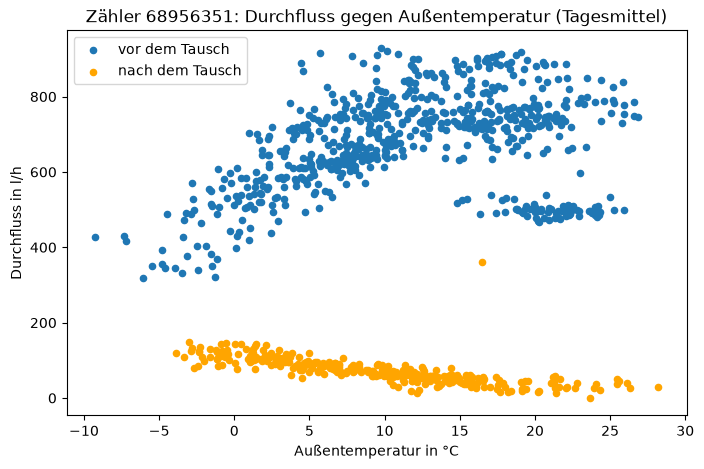

In [23]:
ax = vor.plot.scatter(x="t_out", y="Volume flow (l/h)", figsize=(8, 5))
nach.plot.scatter(x="t_out", y="Volume flow (l/h)", color="orange", ax=ax)
ax.set_title("Zähler 68956351: Durchfluss gegen Außentemperatur (Tagesmittel)")
ax.set_xlabel("Außentemperatur in °C")
ax.set_ylabel("Durchfluss in l/h")
ax.legend(["vor dem Tausch", "nach dem Tausch"])

In [24]:
ax.figure.savefig(BILDER / "27_ventil_kennlinie.png", bbox_inches="tight")

- Nach dem Tausch (orange): Je kälter, desto mehr Wasser, ab etwa 15 °C flach (Heizgrenze, nur noch Warmwasser). So soll eine Station regeln.
- Vor dem Tausch (blau): umgekehrt, am meisten Wasser an warmen Tagen. Das Ventil hat nicht nach Bedarf geregelt.
- Bei Tagen um 0 °C flossen vorher rund 530 l/h, nachher rund 110 l/h. Am Wetter lag der Unterschied also nicht.

**Warum nur ganze Tage ab November 2022?** Vor November 2022 zeigen die Plots fast nichts, obwohl die Reihe 2021 beginnt. Vorhandene Werte je Jahr und die Uhrzeit der frühen Werte:

In [25]:
df.groupby(df["Timestamp"].dt.year)["Return temperature (°C)"].count()

Timestamp
2021      61
2022    1492
2023    8754
2024    8781
2025    4595
Name: Return temperature (°C), dtype: int64

In [26]:
df[df["Timestamp"] < "2022-01-01"].dropna()["Timestamp"].dt.hour.value_counts()

Timestamp
23    61
Name: count, dtype: int64

- 2021 gibt es genau 61 Werte, alle um 23 Uhr. Bis Ende Oktober 2022 lieferte der Zähler nur einen Wert je Tag, erst danach Stundenwerte (siehe auch Notebook 00).
- Diese Lücken zu füllen, hieße 23 von 24 Stunden zu erfinden. Deshalb arbeiten die Modelle nur mit vollständigen Tagen (Abschnitt 5) und praktisch erst ab November 2022.

### 7.2 Sommernacht: das Merkmal des Ventils

- Ein Ventil, das nicht schließt, sieht man am besten im Sommer nachts. Dann wird nicht geheizt und kaum Warmwasser gezapft, eigentlich sollte fast nichts fließen.
- Median des Durchflusses im Sommer 2024 zwischen 0 und 5 Uhr, erst für das Beispiel, dann für eine Station ohne Befund (80912169, begangen im November 2024, der ganze Sommer liegt davor).

In [27]:
sommer = df[(df["Timestamp"] >= "2024-06-01") & (df["Timestamp"] < "2024-09-01")]
nacht = sommer[sommer["Timestamp"].dt.hour < 5]
nacht["Volume flow (l/h)"].median()

np.float64(520.5)

In [28]:
d169 = pd.read_csv(METER_DIR / "80912169.csv", parse_dates=["Timestamp"])

In [29]:
sommer169 = d169[(d169["Timestamp"] >= "2024-06-01") & (d169["Timestamp"] < "2024-09-01")]
nacht169 = sommer169[sommer169["Timestamp"].dt.hour < 5]
nacht169["Volume flow (l/h)"].median()

np.float64(0.0)

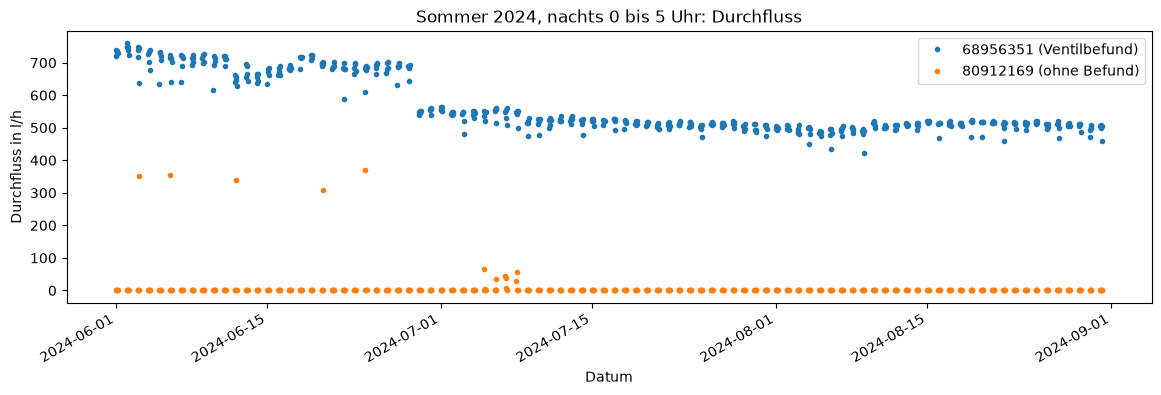

In [30]:
ax = nacht.plot(x="Timestamp", y="Volume flow (l/h)", style=".", figsize=(14, 4))
nacht169.plot(x="Timestamp", y="Volume flow (l/h)", style=".", ax=ax)
ax.set_title("Sommer 2024, nachts 0 bis 5 Uhr: Durchfluss")
ax.set_xlabel("Datum")
ax.set_ylabel("Durchfluss in l/h")
ax.legend(["68956351 (Ventilbefund)", "80912169 (ohne Befund)"])

In [31]:
ax.figure.savefig(BILDER / "27_sommernacht.png", bbox_inches="tight")

- Die Ventilstation hat in Sommernächten im Median 520 l/h, die Station ohne Befund 0 l/h. Dort gibt es nur einzelne Spitzen, etwa durch Warmwasser.
- Wegen dieser Spitzen der Median und nicht der Mittelwert: Einzelne Ausreißer verschieben ihn kaum.

Gilt das für alle 11 Ventilstationen, und wie sieht es bei den Stationen ohne Ventilbefund aus?

In [32]:
ventil = lab[lab["ventil"] == True]["zaehler"]
ventil

7     68956351
10    68956355
16    68956372
19    69527345
21    72135441
22    72135442
26    72167782
29    80912154
45    80912182
47    80912189
50    80912193
Name: zaehler, dtype: int64

In [33]:
nachtfluss = {}

for z in ventil:
    d= pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    s= d[(d["Timestamp"] >= "2024-06-01") & (d["Timestamp"] < "2024-09-01")]
    n= s[s["Timestamp"].dt.hour < 5]
    nachtfluss[z] = n["Volume flow (l/h)"].median()

In [34]:
pd.Series(nachtfluss).sort_values()

80912193      0.0
80912189      0.0
72135442     30.0
72135441     45.5
69527345     56.5
68956355     67.0
68956372    359.0
80912154    494.5
68956351    520.5
80912182    551.0
72167782    753.0
dtype: float64

In [35]:
kein_ventil = lab[lab["ventil"] == False]["zaehler"]

In [36]:
nachtfluss_ohne = {}

for z in kein_ventil:
    d= pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    s= d[(d["Timestamp"] >= "2024-06-01") & (d["Timestamp"] < "2024-09-01")]
    n= s[s["Timestamp"].dt.hour < 5]
    nachtfluss_ohne[z] = n["Volume flow (l/h)"].median()

In [37]:
pd.Series(nachtfluss_ohne).describe()

count     42.000000
mean       6.690476
std       22.442868
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max      121.000000
dtype: float64

- 9 der 11 Ventilstationen haben in Sommernächten Durchfluss, 5 davon über 300 l/h. Bei 2 sieht man nichts.
- Von den 42 Stationen ohne Ventilbefund haben die meisten 0 l/h. Einige wenige haben auch Durchfluss, höchstens 121 l/h. Vielleicht wurde dort bei der Begehung etwas übersehen.
- Eine Grenze „ab X l/h ist das Ventil verdächtig“ ist deshalb immer ein Kompromiss zwischen gefundenen Ventilen und Fehlalarmen. Das bewertet die AUC in Abschnitt 9.

Ist die Sommernacht nur für das Ventil auffällig? Für jede Fehlerart der Anteil der Stationen mit Durchfluss in Sommernächten, mit und ohne Befund:

In [38]:
alle_nacht = {**nachtfluss, **nachtfluss_ohne}
lab["nachtfluss"] = lab["zaehler"].map(alle_nacht)

for b in befunde:
    mit = lab[lab[b] == 1].dropna(subset=["nachtfluss"])
    ohne = lab[lab[b] == 0].dropna(subset=["nachtfluss"])
    print(f"{b:20s} mit Befund: {(mit['nachtfluss'] > 0).mean():.0%}   ohne Befund: {(ohne['nachtfluss'] > 0).mean():.0%}")

ventil               mit Befund: 82%   ohne Befund: 12%
daemmung             mit Befund: 32%   ohne Befund: 23%
filter               mit Befund: 24%   ohne Befund: 29%
durchfluss           mit Befund: 22%   ohne Befund: 29%
temperatur           mit Befund: 30%   ohne Befund: 20%
ueberdimensioniert   mit Befund: 22%   ohne Befund: 19%


- Nur beim Ventil ist der Unterschied groß: 82 % gegen 12 %.
- Bei allen anderen Befunden läuft nachts mit und ohne Befund ungefähr gleich oft Wasser (Unterschied höchstens 10 Prozentpunkte).
- Die Sommernacht ist also ein Ventil-Merkmal. Die anderen Fehlerarten brauchen eigene Kennzahlen.

### 7.3 Die anderen Fehlerarten an je einem Beispiel

- Je Fehlerart eine Station, bei der möglichst nur dieser eine Befund notiert ist und das Datum der Begehung bekannt ist. Sonst weiß man nicht, welcher Befund was verursacht.

In [39]:
anzahl = lab[["ventil", "daemmung", "filter", "durchfluss", "temperatur"]].sum(axis=1)
mit_datum = lab["erste_begehung"].notna()

for b in befunde:
    kandidaten = lab[(lab[b] == 1) & (anzahl <= 1) & mit_datum]
    print(b, list(kandidaten["zaehler"]))

ventil []
daemmung [69527340, 80912163]
filter [68956352, 80912174]
durchfluss [80912173, 80912197]
temperatur [68956344, 69631918, 72167784, 80912162]
ueberdimensioniert [80912173, 80912197]


- Beim Ventil gibt es keine Station mit nur diesem Befund, deshalb in 7.1 die erste Ventilstation.
- Für Dämmung, Filter und Temperatur jeweils die erste Station der Liste.
- Durchfluss und Überdimensionierung: 80912173 und 80912197 haben beides. 80912173 steht für die Überdimensionierung, 80912197 für den Durchfluss.

In [40]:
beispiele = {
    "daemmung": 69527340,
    "filter": 68956352,
    "durchfluss": 80912197,
    "temperatur": 68956344,
    "ueberdimensioniert": 80912173,
}

for b, z in beispiele.items():
    datum = lab[lab["zaehler"] == z]["erste_begehung"].iloc[0]
    print(b, z, datum)

daemmung 69527340 2024-11-19 00:00:00
filter 68956352 2024-09-18 00:00:00
durchfluss 80912197 2024-09-20 00:00:00
temperatur 68956344 2024-09-20 00:00:00
ueberdimensioniert 80912173 2024-09-10 00:00:00


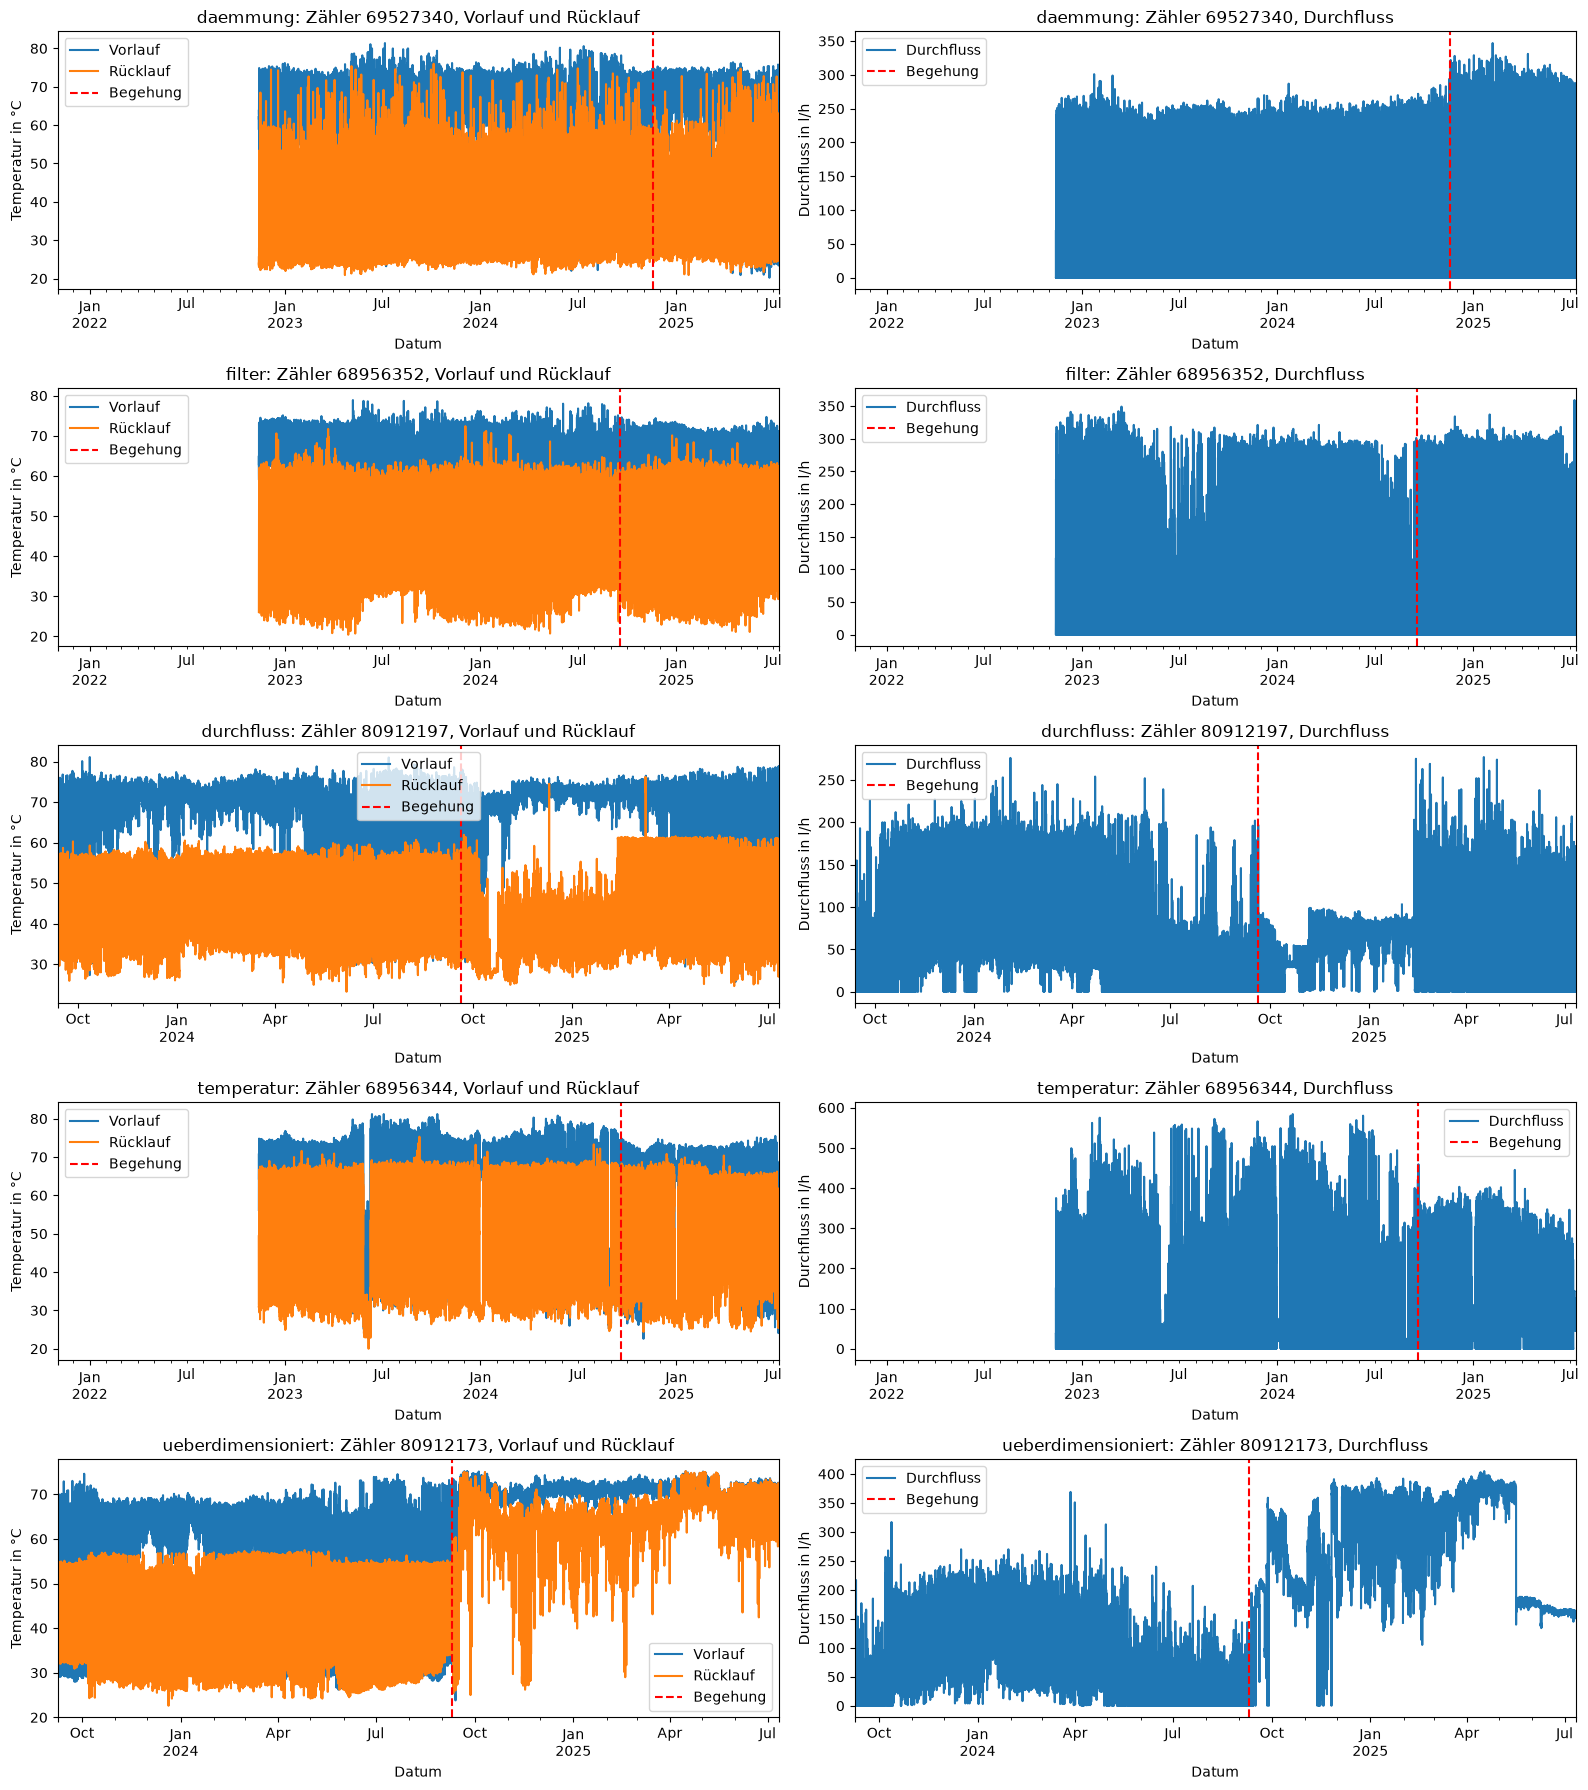

In [41]:
fig, axes = plt.subplots(5, 2, figsize=(16, 18))

for i, (b, z) in enumerate(beispiele.items()):
    d = pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    datum = pd.Timestamp(lab[lab["zaehler"] == z]["erste_begehung"].iloc[0])

    ax = axes[i, 0]
    d.plot(x="Timestamp", y=["Flow temperature (°C)", "Return temperature (°C)"], ax=ax)
    ax.axvline(datum, color="red", linestyle="--")
    ax.set_title(f"{b}: Zähler {z}, Vorlauf und Rücklauf")
    ax.set_xlabel("Datum")
    ax.set_ylabel("Temperatur in °C")
    ax.legend(["Vorlauf", "Rücklauf", "Begehung"])

    ax = axes[i, 1]
    d.plot(x="Timestamp", y="Volume flow (l/h)", ax=ax)
    ax.axvline(datum, color="red", linestyle="--")
    ax.set_title(f"{b}: Zähler {z}, Durchfluss")
    ax.set_xlabel("Datum")
    ax.set_ylabel("Durchfluss in l/h")
    ax.legend(["Durchfluss", "Begehung"])

fig.tight_layout()

In [42]:
fig.savefig(BILDER / "27_beispiele_befunde.png", bbox_inches="tight")

- **Dämmung (69527340):** An der Begehung ändert sich nichts Sichtbares, weder bei den Temperaturen noch beim Durchfluss.
- **Filter (68956352):** Auf den ersten Blick ändert sich wenig.
- **Durchfluss (80912197):** Nach der Begehung sieht der Verlauf anders aus, von Januar bis März 2025 läuft der Durchfluss meist um 80 l/h. Was dort los war, ist nicht bekannt.
- **Temperatur (68956344):** Im Verlauf über Monate sieht man nichts. Der Sollwert wurde nur tagsüber gesenkt, das zeigt erst das Tagesprofil (unten).
- **Überdimensioniert (80912173):** Nach der Begehung laufen Durchfluss und Rücklauf höher als vorher. Das Verkleinern des Vertrags ändert an der Station nichts. Bei derselben Begehung wurde aber auch der Durchfluss neu eingestellt.

**Temperatur über den Tag.** Der Sollwert wird tagsüber gesenkt. Das sieht man nicht im Verlauf über Monate, sondern nur im Tagesprofil: Median des Rücklaufs je Stunde im Winter vor und nach der Begehung.

In [43]:
d344 = pd.read_csv(METER_DIR / "68956344.csv", parse_dates=["Timestamp"])
winter_vor = d344[(d344["Timestamp"] >= "2023-10-01") & (d344["Timestamp"] < "2024-04-01")]
winter_nach = d344[(d344["Timestamp"] >= "2024-10-01") & (d344["Timestamp"] < "2025-04-01")]

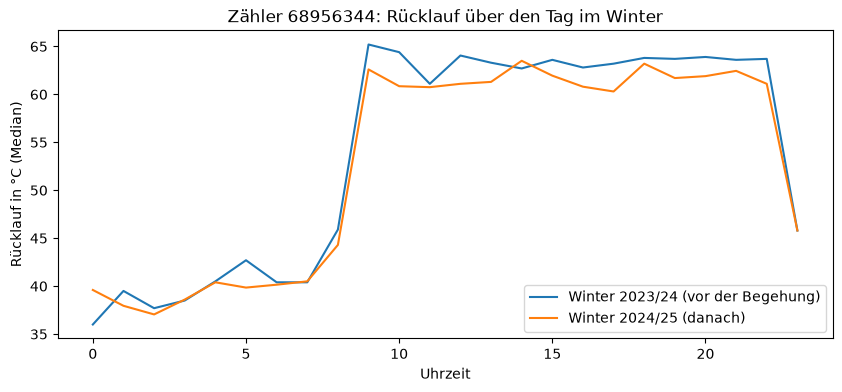

In [44]:
ax = winter_vor.groupby(winter_vor["Timestamp"].dt.hour)["Return temperature (°C)"].median().plot(figsize=(10, 4))
winter_nach.groupby(winter_nach["Timestamp"].dt.hour)["Return temperature (°C)"].median().plot(ax=ax)
ax.set_title("Zähler 68956344: Rücklauf über den Tag im Winter")
ax.set_xlabel("Uhrzeit")
ax.set_ylabel("Rücklauf in °C (Median)")
ax.legend(["Winter 2023/24 (vor der Begehung)", "Winter 2024/25 (danach)"])

- Tagsüber liegt der Rücklauf nach der Begehung meist 1 bis 3 K niedriger. Die Änderung ist da, aber klein und nicht in jeder Stunde gleich.

**Überdimensioniert: Leistung gegen Vertrag.** Bei 80912173 wurde der Vertrag von 10 auf 8 kW verkleinert. Wie viel Leistung hat die Station vorher wirklich gebraucht?

In [45]:
d173 = pd.read_csv(METER_DIR / "80912173.csv", parse_dates=["Timestamp"])
winter173 = d173[(d173["Timestamp"] >= "2023-10-01") & (d173["Timestamp"] < "2024-04-01")]
winter173["Power (kW)"].quantile(0.99)

np.float64(6.748919999999996)

- Selbst in den 1 % stärksten Stunden des Winters braucht die Station nur 6,7 kW, also zwei Drittel des alten Vertrags von 10 kW.
- Das sieht man nur, wenn man die Leistung auf den Vertrag bezieht, nicht am Verlauf.

**Kennlinie vor und nach der Begehung** für dieselben Beispielstationen, wie beim Ventil in 7.1:

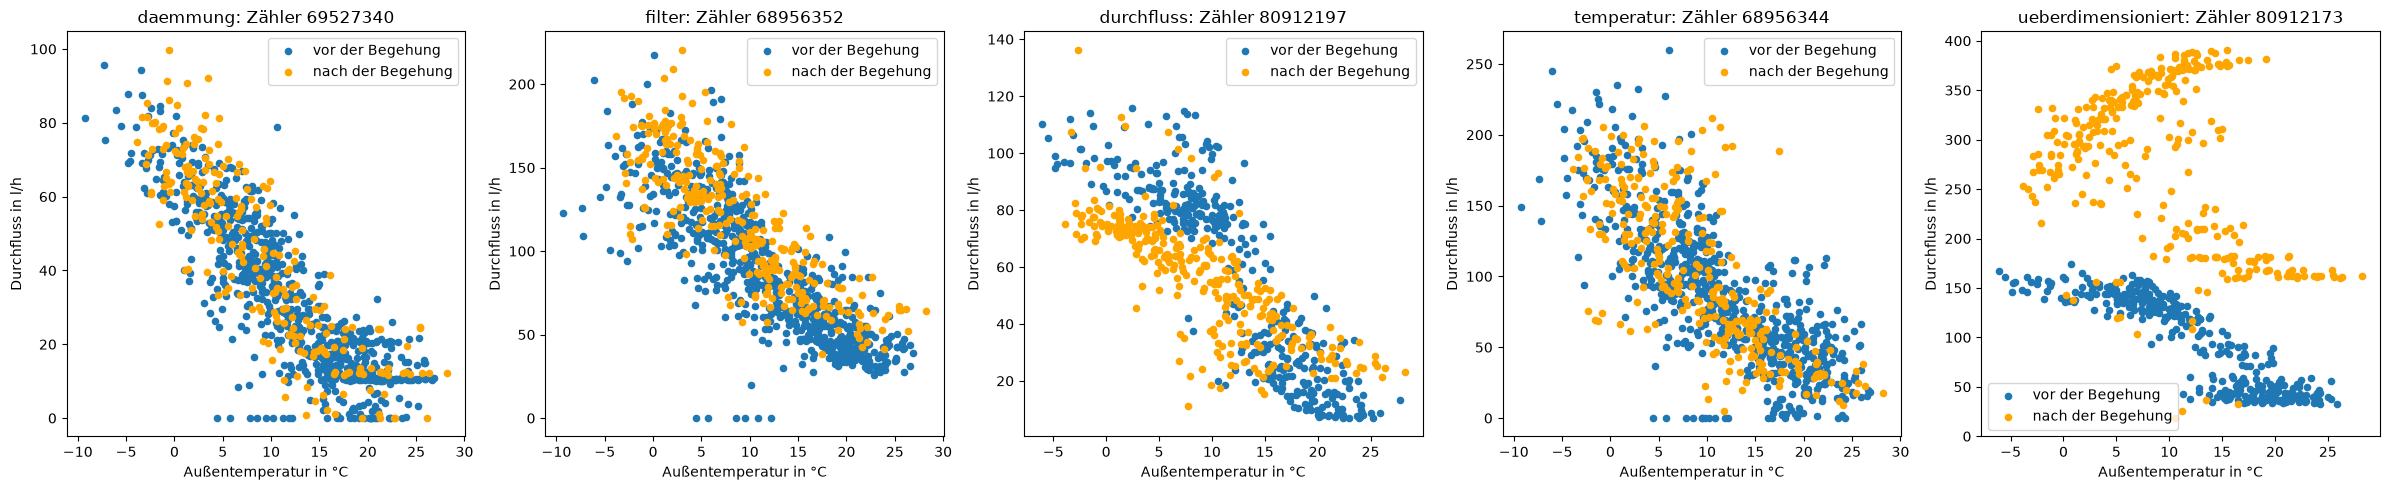

In [46]:
fig, axes = plt.subplots(1, 5, figsize=(24, 5))

for ax, (b, z) in zip(axes, beispiele.items()):
    d = pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    datum = lab[lab["zaehler"] == z]["erste_begehung"].iloc[0]
    w = load_outdoor_temperature(d["Timestamp"].min(), d["Timestamp"].max())
    t = d.merge(w, left_on="Timestamp", right_on="timestamp").resample("D", on="Timestamp").mean(numeric_only=True)
    t_vor = t[(t.index >= "2022-11-01") & (t.index < datum)]
    t_nach = t[t.index >= datum]

    t_vor.plot.scatter(x="t_out", y="Volume flow (l/h)", ax=ax)
    t_nach.plot.scatter(x="t_out", y="Volume flow (l/h)", color="orange", ax=ax)
    ax.set_title(f"{b}: Zähler {z}")
    ax.set_xlabel("Außentemperatur in °C")
    ax.set_ylabel("Durchfluss in l/h")
    ax.legend(["vor der Begehung", "nach der Begehung"])

fig.tight_layout()

- **Dämmung:** vorher und nachher dieselbe Kennlinie.
- **Filter:** fast gleich, an kalten Tagen fließt nach dem Reinigen etwas mehr Wasser.
- **Durchfluss:** Nach dem Einstellen fließt bei mittleren Temperaturen (5 bis 12 °C) weniger Wasser.
- **Temperatur:** keine Änderung in den Tagesmitteln.
- **Überdimensioniert:** Nach der Begehung fließt mehr Wasser, an warmen Tagen sogar mehr als an kalten. Über die Überdimensionierung selbst sagt das nichts.
- Eine klare Änderung der Kennlinie zeigen nur Ventil und Durchfluss.

### 7.4 Befunde kommen gemeinsam vor

- Viele Stationen haben mehrere Befunde auf einmal. Wie oft kommen zwei Befunde zusammen vor?

In [47]:
zusammen = pd.DataFrame(index=befunde, columns=befunde)
for a in befunde:
    for b in befunde:
        zusammen.loc[a, b] = ((lab[a] == 1) & (lab[b] == 1)).sum()
zusammen

,ventil,daemmung,filter,durchfluss,temperatur,ueberdimensioniert
ventil,11,6,5,5,7,1
daemmung,6,23,11,9,15,5
filter,5,11,26,10,18,4
durchfluss,5,9,10,20,13,8
temperatur,7,15,18,13,36,4
ueberdimensioniert,1,5,4,8,4,9


- Auf der Diagonale steht die Zahl der Fälle je Befund.
- 6 der 11 Ventilstationen haben auch einen Dämmungsbefund, 5 einen Filterbefund. Der Sollwert wurde bei 36 Stationen gesenkt und ist fast überall dabei.
- 8 der 9 überdimensionierten Stationen hatten auch einen Durchfluss-Befund. Beim Verkleinern des Vertrags wurde der Durchfluss offenbar gleich mit eingestellt.
- Folge: Eine Kennzahl, die eigentlich zum Ventil gehört, kann auch bei Dämmung oder Filter auffallen. Jede Fehlerart wird deshalb einzeln gegen „kein Befund dieser Art“ geprüft.

### 7.5 Was daraus folgt

| Befund | sichtbar in den Stundenwerten? | wo man suchen muss |
|---|---|---|
| Ventil | ja, deutlich | Durchfluss in Sommernächten, Kennlinie gegen Außentemperatur |
| Überdimensioniert | nur im Verhältnis | Spitzenleistung gegen den Vertrag vor der Begehung |
| Temperatur (Sollwert) | kaum | Rücklauf tagsüber |
| Durchfluss | an einer Station | Durchfluss bei mittleren Temperaturen |
| Dämmung, Filter | nicht sichtbar | offen |

- Jede Fehlerart braucht ihre eigene Kennzahl. Abschnitt 8 baut die Kennzahlen für die Modelle, Abschnitt 9 prüft je Fehlerart eine einzige, vorher festgelegte Kennzahl.
- Nur Daten vor der Begehung, nur vollständige Tage ab November 2022.

## 8 Kennzahlen vor der Begehung

- Logistische Regression, XGBoost und das K-Means in Notebook 26 brauchen je Zähler eine Zeile mit Zahlen.
- Jede Kennzahl steht für ein Fehlerbild.
- Gerechnet wird nur mit Daten vor der ersten Begehung, spätestens bis zum Stichtag.

| Kennzahl | Zeitraum | Rechnung | Fehlerbild |
|---|---|---|---|
| `sommer_nachtfluss_lph` | Sommer 2024, 0–5 Uhr | Median des Durchflusses | Wasser läuft, obwohl niemand heizt: Ventil schließt nicht |
| `sommer_durchlauf_anteil` | Sommer 2024, 0–5 Uhr | Anteil der Stunden mit ≥ 5 l/h | dasselbe, unempfindlich gegen einzelne Spitzen |
| `sommer_nacht_spreizung_k` | Sommer 2024, 0–5 Uhr | Median der Spreizung, wenn Wasser fließt | kaum Spreizung: Wasser läuft ungenutzt durch |
| `winter_ruecklauf_bei_0c` | Winter 23/24 | Gerade Tagesmittel Rücklauf gegen Außentemperatur, Wert bei 0 °C | schlechte Auskühlung, wetterbereinigt |
| `winter_spreizung_last_k` | Winter 23/24 | mittlere Spreizung bei Leistung > 0,5 kW | schlechter Wärmeübergang |
| `winter_ruecklauf_p90` | Winter 23/24 | 90-%-Quantil des Rücklaufs | zeitweise sehr heißer Rücklauf |
| `winter_fluss_cv` | Winter 23/24 | Streuung / Mittel des Durchflusses unter Last | unruhige Regelung |
| `winter_nacht_tag_fluss` | Winter 23/24 | Durchfluss 0–5 Uhr / 8–20 Uhr (Mediane) | fehlende Nachtabsenkung |
| `auslastung` | Winter 23/24 | 99-%-Quantil der Leistung / Anschlusswert aus `Nodes_Edges.ods` | überdimensionierter Anschluss |
| `auslastung_vertrag` | Winter 23/24 | 99-%-Quantil der Leistung / Vertragsleistung vor der Begehung (Protokoll) | dasselbe, nur für begangene Zähler (Begründung in Abschnitt 8.1) |
| `sommerlast_anteil` | 09/2023–08/2024 | mittlere Leistung im Sommer / im ganzen Jahr | hohe Grundlast (Zirkulation, Verluste) |

- Für die Einstufung in Notebook 26 kommen drei Größen dazu. Sie beschreiben, wie eine Station ihre Leistung regelt (Winter 23/24, nur Stunden mit Leistung > 0,5 kW, Durchfluss > 1 l/h und Spreizung > 1 K):

| Kennzahl | Rechnung | Bedeutung |
|---|---|---|
| `anteil_volumenstrom` | cov(log P, log V) / var(log P) | nahe 1: Durchfluss folgt der Last; nahe 0: er läuft konstant weiter |
| `streubreite_betriebspunkte` | √(var log V + var log ΔT) | gleichbleibender gegen springenden Betrieb |
| `ruecklauf_lastgewichtet` | Mittel des Rücklaufs, gewichtet mit der Leistung | wie heiß das Wasser zurückkommt, wenn es darauf ankommt |

In [48]:
MIN_LASTSTUNDEN = 200


def kennzahlen(g):
    w = g[(g["timestamp"] >= WINTER[0]) & (g["timestamp"] < WINTER[1])]
    s = g[(g["timestamp"] >= SOMMER[0]) & (g["timestamp"] < SOMMER[1])]
    k = {"stunden_winter": int(w["durchfluss"].notna().sum()), "stunden_sommer": int(s["durchfluss"].notna().sum())}

    #Sommernächte
    nacht = s[s["timestamp"].dt.hour <= 5].dropna(subset=["durchfluss"])
    fliesst = nacht[nacht["durchfluss"] >= 5]
    k["sommer_nachtfluss_lph"] = nacht["durchfluss"].median()
    k["sommer_durchlauf_anteil"] = (nacht["durchfluss"] >= 5).mean() if len(nacht) else np.nan
    k["sommer_nacht_spreizung_k"] = fliesst["spreizung"].median() if len(fliesst) >= 20 else np.nan

    #Winter
    tag = w.groupby(w["timestamp"].dt.floor("D"))[["ruecklauf", "aussen"]].mean().dropna()
    tag = tag[tag["aussen"] <= 15]
    k["winter_ruecklauf_bei_0c"] = np.polyfit(tag["aussen"], tag["ruecklauf"], 1)[1] if len(tag) >= 30 else np.nan
    last = w[(w["leistung"] > 0.5) & (w["durchfluss"] > 1) & (w["spreizung"] > 1)].dropna(subset=["ruecklauf"])
    k["winter_spreizung_last_k"] = last["spreizung"].mean()
    k["winter_ruecklauf_p90"] = w["ruecklauf"].quantile(0.9)
    k["winter_fluss_cv"] = last["durchfluss"].std() / last["durchfluss"].mean() if len(last) else np.nan
    tags = w.loc[w["timestamp"].dt.hour.between(8, 20), "durchfluss"].median()
    nachts = w.loc[w["timestamp"].dt.hour <= 5, "durchfluss"].median()
    k["winter_nacht_tag_fluss"] = nachts / tags if tags > 0 else np.nan
    k["winter_spitzenlast_kw"] = w["leistung"].quantile(0.99)
    jahr = g[(g["timestamp"] >= "2023-09-01") & (g["timestamp"] < "2024-09-01")]
    k["sommerlast_anteil"] = s["leistung"].mean() / jahr["leistung"].mean() if jahr["leistung"].mean() > 0 else np.nan

    #Wie regelt die Station? (für Notebook 17) - leer, wenn es zu wenige Laststunden gibt
    k["anteil_volumenstrom"] = k["streubreite_betriebspunkte"] = k["ruecklauf_lastgewichtet"] = np.nan
    if len(last) >= MIN_LASTSTUNDEN:
        log_p, log_v, log_d = np.log(last["leistung"]), np.log(last["durchfluss"]), np.log(last["spreizung"])
        k["anteil_volumenstrom"] = np.cov(log_p, log_v, bias=True)[0, 1] / np.var(log_p)
        k["streubreite_betriebspunkte"] = np.sqrt(np.var(log_v) + np.var(log_d))
        k["ruecklauf_lastgewichtet"] = np.average(last["ruecklauf"], weights=last["leistung"])
    return pd.Series(k)


#Jeder Zähler nur bis zu seiner ersten Begehung, spätestens bis zum Stichtag
grenze = labels["erste_begehung"].clip(upper=STICHTAG).reindex(sorted(zaehler_mit_reihe)).fillna(STICHTAG)
vor = stunden[stunden["timestamp"] < stunden["zaehler"].map(grenze)]
kz = vor.groupby("zaehler").apply(kennzahlen)

anschluss = pd.read_csv(PROCESSED / "hast_features.csv").set_index("Zählernummer")["anschlusswert_kw"]
kz["auslastung"] = kz["winter_spitzenlast_kw"] / anschluss.reindex(kz.index)
kz["auslastung_vertrag"] = kz["winter_spitzenlast_kw"] / labels["vertrag_alt_kw"].reindex(kz.index)
kz = kz.drop(columns="winter_spitzenlast_kw")
print(f"{len(kz)} Zähler, {kz.shape[1]} Spalten")
kz.round(2).head(10)

91 Zähler, 16 Spalten


,stunden_winter,stunden_sommer,sommer_nachtfluss_lph,sommer_durchlauf_anteil,sommer_nacht_spreizung_k,winter_ruecklauf_bei_0c,winter_spreizung_last_k,winter_ruecklauf_p90,winter_fluss_cv,winter_nacht_tag_fluss,sommerlast_anteil,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet,auslastung,auslastung_vertrag
zaehler,,,,,,,,,,,,,,,,
53198226,3467.0,2206.0,10.0,0.66,14.2,44.78,32.07,54.50,0.65,0.34,0.10,0.96,0.83,42.95,1.31,NaN
58177363,4389.0,0.0,NaN,NaN,NaN,42.14,32.33,47.60,0.62,0.62,NaN,0.84,0.60,39.22,NaN,NaN
58177384,923.0,0.0,NaN,NaN,NaN,57.14,25.31,57.50,0.47,0.58,NaN,1.17,0.59,51.06,NaN,NaN
58202380,4386.0,0.0,NaN,NaN,NaN,56.75,NaN,68.20,NaN,1.08,NaN,NaN,NaN,NaN,NaN,NaN
61620222,4391.0,0.0,NaN,NaN,NaN,46.59,24.54,58.50,0.71,0.00,NaN,0.97,0.91,44.58,NaN,NaN
65273846,4390.0,2206.0,0.0,0.01,NaN,28.73,37.22,41.50,0.81,0.00,0.31,1.02,0.65,31.26,1.84,1.84
66761022,4381.0,0.0,NaN,NaN,NaN,61.24,12.63,71.00,0.37,0.85,NaN,0.56,0.64,62.33,0.48,NaN
68956339,3773.0,2197.0,0.0,0.00,NaN,48.89,24.45,59.50,0.58,0.39,0.09,0.89,0.71,49.33,0.78,NaN
68956342,4390.0,2206.0,0.0,0.18,21.5,48.37,26.83,51.71,0.83,0.42,0.08,0.99,0.91,43.81,0.79,NaN


In [49]:
kz.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
stunden_winter,91.0,3963.21,875.78,0.00,3467.00,4390.00,4390.00,4391.00
stunden_sommer,91.0,1974.82,624.63,0.00,2205.00,2206.00,2206.00,2206.00
sommer_nachtfluss_lph,85.0,143.52,616.79,0.00,0.00,0.00,23.50,5165.00
sommer_durchlauf_anteil,85.0,0.36,0.38,0.00,0.06,0.16,0.71,1.00
sommer_nacht_spreizung_k,71.0,12.12,10.07,-14.70,2.55,12.00,18.60,35.70
winter_ruecklauf_bei_0c,88.0,47.26,9.89,28.48,41.98,46.20,53.20,68.99
winter_spreizung_last_k,89.0,25.12,8.36,4.02,20.61,27.43,30.57,39.80
winter_ruecklauf_p90,90.0,57.93,10.37,33.61,51.73,56.55,64.32,80.62
winter_fluss_cv,89.0,0.56,0.24,0.08,0.42,0.60,0.71,1.07
winter_nacht_tag_fluss,83.0,0.68,0.40,0.00,0.40,0.66,1.02,2.15


- `count`: für wie viele der 91 Zähler die Kennzahl berechnet werden konnte. Von den 93 Zählern aus Notebook 00 fehlen 80912191 und 81019433: Sie haben vor dem Stichtag keine Messwerte.
- `min` und `max`: ob die Werte physikalisch Sinn ergeben. Ein Durchlaufanteil liegt zwischen 0 und 1, ein Rücklauf bei 0 °C typischerweise zwischen 30 und 70 °C.
- `auslastung_vertrag` gibt es nur für begangene Zähler. Die Vertragsleistung vor der Begehung steht nur im Begehungsprotokoll.

### 8.1 Ein Datenfehler beim Anschlusswert

- Für die Auslastung gibt es zwei Bezugsgrößen: den Anschlusswert aus `Nodes_Edges.ods` und die Vertragsleistung vor der Begehung aus dem Protokoll. Eigentlich sollten sie gleich sein.
- Die Zelle vergleicht beide bei den Zählern, deren Vertrag bei der Begehung verkleinert wurde.

In [50]:
vertrag = labels[["vertrag_alt_kw", "vertrag_neu_kw"]].dropna().join(anschluss.rename("anschlusswert_kw"))
verkleinert = vertrag[vertrag["vertrag_neu_kw"] < vertrag["vertrag_alt_kw"]]
gleich_neu = (verkleinert["anschlusswert_kw"] == verkleinert["vertrag_neu_kw"]).sum()
gleich_alt = (verkleinert["anschlusswert_kw"] == verkleinert["vertrag_alt_kw"]).sum()
print(f"{len(verkleinert)} Verträge wurden bei der Begehung verkleinert.")
print(f"  Anschlusswert in Nodes_Edges = NEUER Wert: {gleich_neu}")
print(f"  Anschlusswert in Nodes_Edges = alter Wert: {gleich_alt}")
verkleinert

9 Verträge wurden bei der Begehung verkleinert.
  Anschlusswert in Nodes_Edges = NEUER Wert: 7
  Anschlusswert in Nodes_Edges = alter Wert: 2


,vertrag_alt_kw,vertrag_neu_kw,anschlusswert_kw
zaehler,,,
68956347,12.0,10.0,10.0
68956356,8.0,6.0,8.0
68956371,8.0,6.0,6.0
68956372,8.0,6.0,6.0
72135486,8.0,6.0,8.0
72167783,17.0,13.0,13.0
80912173,10.0,8.0,8.0
80912180,14.0,12.0,12.0
80912197,10.0,8.0,8.0


- `Nodes_Edges.ods` wurde offenbar nach den Begehungen gepflegt: Bei 7 der 9 verkleinerten Verträge steht dort schon der neue, kleinere Wert.
- Wer die Auslastung auf den Anschlusswert bezieht, sieht bei genau diesen Stationen eine normale Auslastung. Das Signal „überdimensioniert“ ist dann weg.
- In der lokalen Vorarbeit war der alte Vertrag die Bezugsgröße. Dort war die Überdimensionierung mit XGBoost erkennbar (AUC bis 0,87).
- Folge: Zum Lernen und Prüfen nimmt Notebook 29 die `auslastung_vertrag`. Für nie begangene Zähler ohne Protokoll bleibt nur der Anschlusswert; für sie ist er aber der aktuelle Vertrag und damit die richtige Größe.

Zur Kennzahl-Zelle oben:
- `kennzahlen()` bekommt die Stunden eines Zählers und gibt eine Zeile mit allen Kennzahlen zurück. Jede Zeile der Funktion entspricht einer Zeile der Tabelle in Abschnitt 8.
- `grenze` schneidet je Zähler alles ab der ersten Begehung ab, spätestens ab dem Stichtag. Bei den im August 2024 begangenen Zählern fehlt damit ein Teil des Sommers. Dafür sieht kein Modell eine Station nach ihrer Reparatur.
- Bei zu wenigen Stunden (zum Beispiel keine 200 Laststunden) bleibt das Feld leer, statt eine Zahl aus Rauschen zu erzeugen.
- Die Auslastung nutzt den Anschlusswert aus Notebook 00 (aus `Nodes_Edges.ods`).

In [51]:
#Von Hand nachgerechnet: Sommer-Nachtdurchfluss des Beispielzählers
g = stunden[(stunden["zaehler"] == BEISPIEL) & (stunden["timestamp"] >= SOMMER[0])
            & (stunden["timestamp"] < min(SOMMER[1], grenze[BEISPIEL]))]
naechte = g[g["timestamp"].dt.hour <= 5]["durchfluss"].dropna()
print(f"Zähler {BEISPIEL}: {len(naechte)} Nachtstunden im Sommer 2024, Median {naechte.median():.1f} l/h")
assert np.isclose(naechte.median(), kz.loc[BEISPIEL, "sommer_nachtfluss_lph"])
print("stimmt mit der Tabelle überein")

fehlend = kz.isna().sum()
print("\nFehlende Werte je Kennzahl (nur > 0):")
fehlend[fehlend > 0].to_frame("Zähler ohne Wert")

Zähler 68956347: 552 Nachtstunden im Sommer 2024, Median 0.0 l/h
stimmt mit der Tabelle überein

Fehlende Werte je Kennzahl (nur > 0):


,Zähler ohne Wert
sommer_nachtfluss_lph,6
sommer_durchlauf_anteil,6
sommer_nacht_spreizung_k,20
winter_ruecklauf_bei_0c,3
winter_spreizung_last_k,2
winter_ruecklauf_p90,1
winter_fluss_cv,2
winter_nacht_tag_fluss,8
sommerlast_anteil,6
anteil_volumenstrom,3


- Rechnet eine Kennzahl für einen Zähler ohne die Funktion nach und prüft mit `assert`, dass dasselbe herauskommt.
- Zeigt, für wie viele Zähler eine Kennzahl fehlt. Meist wurde im Sommer 2024 oder im Winter 23/24 zu wenig gemessen.

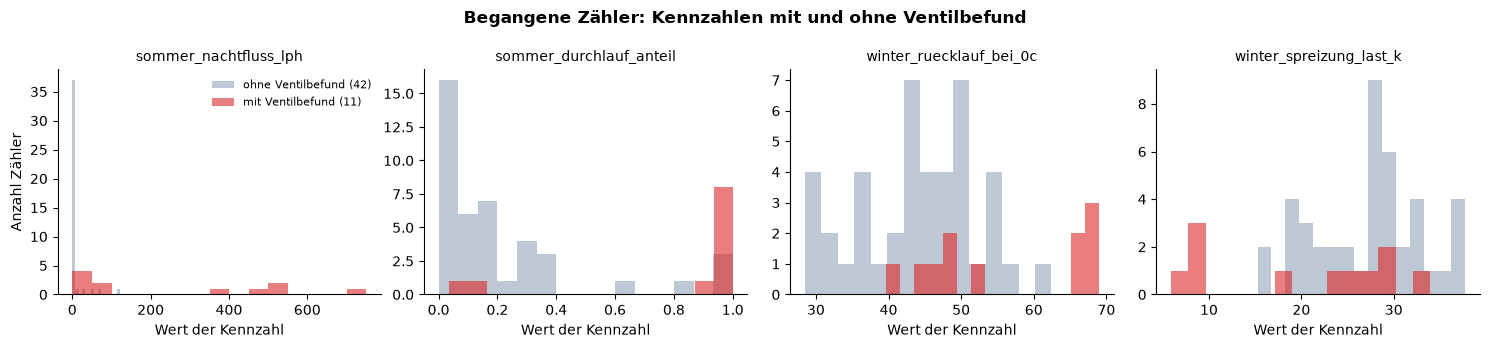

In [52]:
vergleich = kz.join(labels[["ventil", "daemmung"]], how="inner")
zeige = ["sommer_nachtfluss_lph", "sommer_durchlauf_anteil", "winter_ruecklauf_bei_0c", "winter_spreizung_last_k"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, spalte in zip(axes, zeige):
    for wert, farbe, name in ((False, "#94A3B8", "ohne Ventilbefund"), (True, "#DC2626", "mit Ventilbefund")):
        werte = vergleich.loc[vergleich["ventil"] == wert, spalte].dropna()
        ax.hist(werte, bins=15, alpha=0.6, color=farbe, label=f"{name} ({len(werte)})")
    ax.set_title(spalte, fontsize=10)
    ax.set_xlabel("Wert der Kennzahl")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Anzahl Zähler")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Begangene Zähler: Kennzahlen mit und ohne Ventilbefund", fontweight="bold")
fig.tight_layout()
plt.show()

- Erster Blick, ob die Kennzahlen die Befunde trennen: je Kennzahl ein Histogramm für begangene Zähler mit und ohne Ventilbefund.

- Der Sommer-Durchlaufanteil trennt das Ventil fast allein: 9 der 11 Zähler mit Ventilbefund hatten im Sommer 2024 in mindestens 90 % der Nachtstunden Durchfluss, ohne Befund nur 3 von 42. Im Median liefen bei den Ventilfällen nachts 67 l/h durch, bei den anderen 0 l/h.
- Auch im Winter gibt es Unterschiede: Rücklauf bei 0 °C im Median 53 °C statt 45 °C, Spreizung unter Last kleiner (24,6 statt 28,2 K). Das passt zur Physik: Läuft Wasser ungenutzt durch, kommt es heiß zurück. Die Verteilungen überlappen aber stark.
- Ausgangslage für die Modelle: Mit dem Sommer ist das Ventil leicht zu finden. Offen ist, ob ein Modell es schon im Winter sieht und ob es für die anderen Fehlerarten überhaupt ein Signal gibt.

## 9 Messlatte: eine Kennzahl je Fehlerart

- Bevor ein Modell lernt, steht die einfachste Lösung: je Fehlerart eine Kennzahl aus der Physik, ohne Lernen. Jedes spätere Modell muss diese Messlatte schlagen, sonst lohnt es sich nicht.
- Die Kennzahl und die erwartete Richtung stehen fest, bevor gerechnet wird. Geht eine Kennzahl in die andere Richtung, gilt die Vermutung als falsch und wird nicht umgedreht. Sonst wäre die Richtung nach dem Ergebnis gewählt und die Zahl zu gut.
- Die Ideen kommen aus Abschnitt 7.

| Befund | Idee | Kennzahl | Erwartung bei Befund |
|---|---|---|---|
| ventil | Ventil schließt nicht, Wasser läuft nachts im Sommer durch | `nachtfluss`: Median Durchfluss Sommer 2024, 0 bis 5 Uhr | höher |
| daemmung | Wasser verliert im Keller zusätzlich Wärme, Rücklauf wird kälter | `winter_ruecklauf`: Median Rücklauf Winter 2023/24 | niedriger |
| filter | Verstopfter Filter bremst das Wasser, es fließt langsamer und kühlt stärker ab | `winter_spreizung`: Median Spreizung im Winter, nur Stunden mit Durchfluss | höher |
| durchfluss | Durchfluss zu hoch eingestellt, bei viel Bedarf fließt mehr als nötig | `fluss_pro_kw`: 99-%-Wert Durchfluss im Winter / Anschlusswert | höher |
| temperatur | Rücklauf tagsüber zu hoch, deshalb wurde der Sollwert gesenkt | `ruecklauf_tag`: Median Rücklauf im Winter, 8 bis 20 Uhr | höher |
| ueberdimensioniert | Vertrag größer als nötig, die Leistung wird nie ausgeschöpft | `auslastung`: 99-%-Wert Leistung im Winter / alter Vertrag | niedriger |

Der 99-%-Wert ist fast das Maximum, aber einzelne Ausreißer verschieben ihn nicht. Die Spreizung nur in Stunden mit Durchfluss, weil sie sonst nichts bedeutet (siehe Abschnitt 3.1).

### 9.1 Kennzahlen je begangener Station

- Gerechnet wird nur auf den begangenen Zählern, denn nur dort gibt es Labels. Winter 2023/24 und Sommer 2024 liegen vor den Begehungen.
- Für `fluss_pro_kw` braucht es den Anschlusswert aus Notebook 00, für die `auslastung` die Vertragsleistung vor der Begehung aus dem Protokoll (siehe 8.1).

In [53]:
anschluss_b = pd.read_csv(ROOT / "data" / "processed" / "hast_features.csv")
anschluss_b = anschluss_b[["Zählernummer", "anschlusswert_kw"]].rename(columns={"Zählernummer": "zaehler"})

In [54]:
zeilen = []
for z in labels.reset_index()["zaehler"]:
    d = pd.read_csv(METER_DIR / f"{z}.csv", parse_dates = ["Timestamp"])
    
    sommer = d[(d["Timestamp"] >= "2024-06-01") & (d["Timestamp"] < "2024-09-01")]
    nacht = sommer[sommer["Timestamp"].dt.hour < 5]
    
    winter = d[(d["Timestamp"] >= "2023-10-01") & (d["Timestamp"] < "2024-04-01")]
    mit_fluss = winter[winter["Volume flow (l/h)"] > 0]
    tagsueber = winter[(winter["Timestamp"].dt.hour >= 8) & (winter["Timestamp"].dt.hour < 20)]
    
    zeilen.append({
        "zaehler": z,
        "nachtfluss": nacht["Volume flow (l/h)"].median(),
        "winter_ruecklauf": winter["Return temperature (°C)"].median(),
        "winter_spreizung": mit_fluss["Temperature difference (°C)"].median(),
        "fluss_p99": winter["Volume flow (l/h)"].quantile(0.99),
        "ruecklauf_tag": tagsueber["Return temperature (°C)"].median(),
        "leistung_p99": winter["Power (kW)"].quantile(0.99),
    })

In [55]:
kz_einfach = pd.DataFrame(zeilen)
tabelle = kz_einfach.merge(labels.reset_index(), on="zaehler")
tabelle = tabelle.merge(anschluss_b, on="zaehler", how="left")

In [56]:
tabelle["fluss_pro_kw"] = tabelle["fluss_p99"] / tabelle["anschlusswert_kw"]
tabelle["auslastung"] = tabelle["leistung_p99"] / tabelle["vertrag_alt_kw"]

In [57]:
tabelle[["zaehler", "nachtfluss", "winter_ruecklauf", "winter_spreizung", "fluss_pro_kw", "ruecklauf_tag", "auslastung"]].describe()

,zaehler,nachtfluss,winter_ruecklauf,winter_spreizung,fluss_pro_kw,ruecklauf_tag,auslastung
count,5.600000e+01,53.000000,54.000000,54.000000,54.000000,54.000000,35.000000
mean,7.514527e+07,59.584906,45.827778,24.343519,39.696032,47.043519,0.963171
std,5.741704e+06,161.718825,12.237110,10.245192,17.575303,12.219556,0.289540
min,6.527385e+07,0.000000,25.400000,0.100000,7.005000,25.500000,0.475710
25%,6.895637e+07,0.000000,37.075000,19.175000,30.093750,38.600000,0.770172
50%,7.216778e+07,0.000000,45.900000,27.300000,33.043000,47.650000,0.950717
75%,8.091217e+07,16.000000,53.750000,30.750000,46.818750,54.650000,1.076316
max,8.101943e+07,753.000000,75.100000,40.600000,105.250000,74.800000,1.838194


- Für 2 bis 3 der 56 begangenen Stationen fehlen Sommer- oder Winterdaten.
- Die `auslastung` gibt es nur für 35 Stationen, weil nur dort der alte Vertrag im Protokoll steht.

### 9.2 Stimmt die Richtung?

- Zuerst eine naheliegende Vermutung: Bei Dämmung verliert das Wasser im Keller weniger Wärme. Dann sollte der Rücklauf anders aussehen. Median des Winter-Rücklaufs mit und ohne Dämmungsbefund, dann dasselbe für das Ventil:

In [58]:
tabelle.groupby("daemmung")["winter_ruecklauf"].median()

daemmung
False    47.6
True     38.6
Name: winter_ruecklauf, dtype: float64

In [59]:
tabelle.groupby("ventil")["winter_ruecklauf"].median()

ventil
False    41.55
True     55.10
Name: winter_ruecklauf, dtype: float64

- Mit Dämmungsbefund ist der Winter-Rücklauf 9 K kälter (38,6 gegen 47,6 °C).
- Beim Ventil ist es umgekehrt, wärmer (55,1 gegen 41,6 °C): Heißes Wasser läuft ungenutzt durch.
- Dieselbe Kennzahl zeigt bei zwei Befunden in entgegengesetzte Richtungen, und 6 der 11 Ventilstationen haben auch einen Dämmungsbefund (7.4). Die Effekte können sich aufheben. Auch das spricht für eine eigene Kennzahl je Befund.

Jetzt alle Befunde mit ihrer Kennzahl aus der Tabelle oben:

In [60]:
plan = {
    "ventil": "nachtfluss",
    "daemmung": "winter_ruecklauf",
    "filter": "winter_spreizung",
    "durchfluss": "fluss_pro_kw",
    "temperatur": "ruecklauf_tag",
    "ueberdimensioniert": "auslastung",
}

for b, k in plan.items():
    mit = tabelle[tabelle[b] == 1][k].median()
    ohne = tabelle[tabelle[b] == 0][k].median()
    print(f"{b:20s} {k:18s} mit Befund: {mit:7.2f}   ohne Befund: {ohne:7.2f}")

ventil               nachtfluss         mit Befund:   67.00   ohne Befund:    0.00
daemmung             winter_ruecklauf   mit Befund:   38.60   ohne Befund:   47.60
filter               winter_spreizung   mit Befund:   25.00   ohne Befund:   28.60
durchfluss           fluss_pro_kw       mit Befund:   31.64   ohne Befund:   34.40
temperatur           ruecklauf_tag      mit Befund:   49.60   ohne Befund:   43.40
ueberdimensioniert   auslastung         mit Befund:    0.67   ohne Befund:    0.97


- **Ventil:** nachts 67 l/h mit Befund, 0 l/h ohne. Richtung stimmt.
- **Dämmung:** Rücklauf 38,6 gegen 47,6 °C, kälter. Richtung stimmt.
- **Filter:** Spreizung 25,0 gegen 28,6 K, also kleiner statt größer. Die Vermutung stimmt nicht.
- **Durchfluss:** 31,6 gegen 34,4 l/h je kW, eher weniger statt mehr. Die Vermutung stimmt nicht.
- **Temperatur:** Rücklauf tagsüber 49,6 gegen 43,4 °C, höher. Richtung stimmt: Wo der Rücklauf tagsüber hoch war, wurde der Sollwert gesenkt.
- **Überdimensioniert:** Auslastung 0,67 gegen 0,97. Stationen mit verkleinertem Vertrag haben vorher nur zwei Drittel davon gebraucht. Richtung stimmt.

Ein Median sagt nur etwas über die Mitte. Wie stark sich die Gruppen überlappen, zeigen Boxplots:

In [61]:
einheit = {
    "nachtfluss": "Durchfluss nachts in l/h",
    "winter_ruecklauf": "Rücklauf in °C",
    "winter_spreizung": "Spreizung in K",
    "fluss_pro_kw": "Durchfluss (99 %) in l/h pro kW",
    "ruecklauf_tag": "Rücklauf tagsüber in °C",
    "auslastung": "Leistung (99 %) / Vertrag",
}

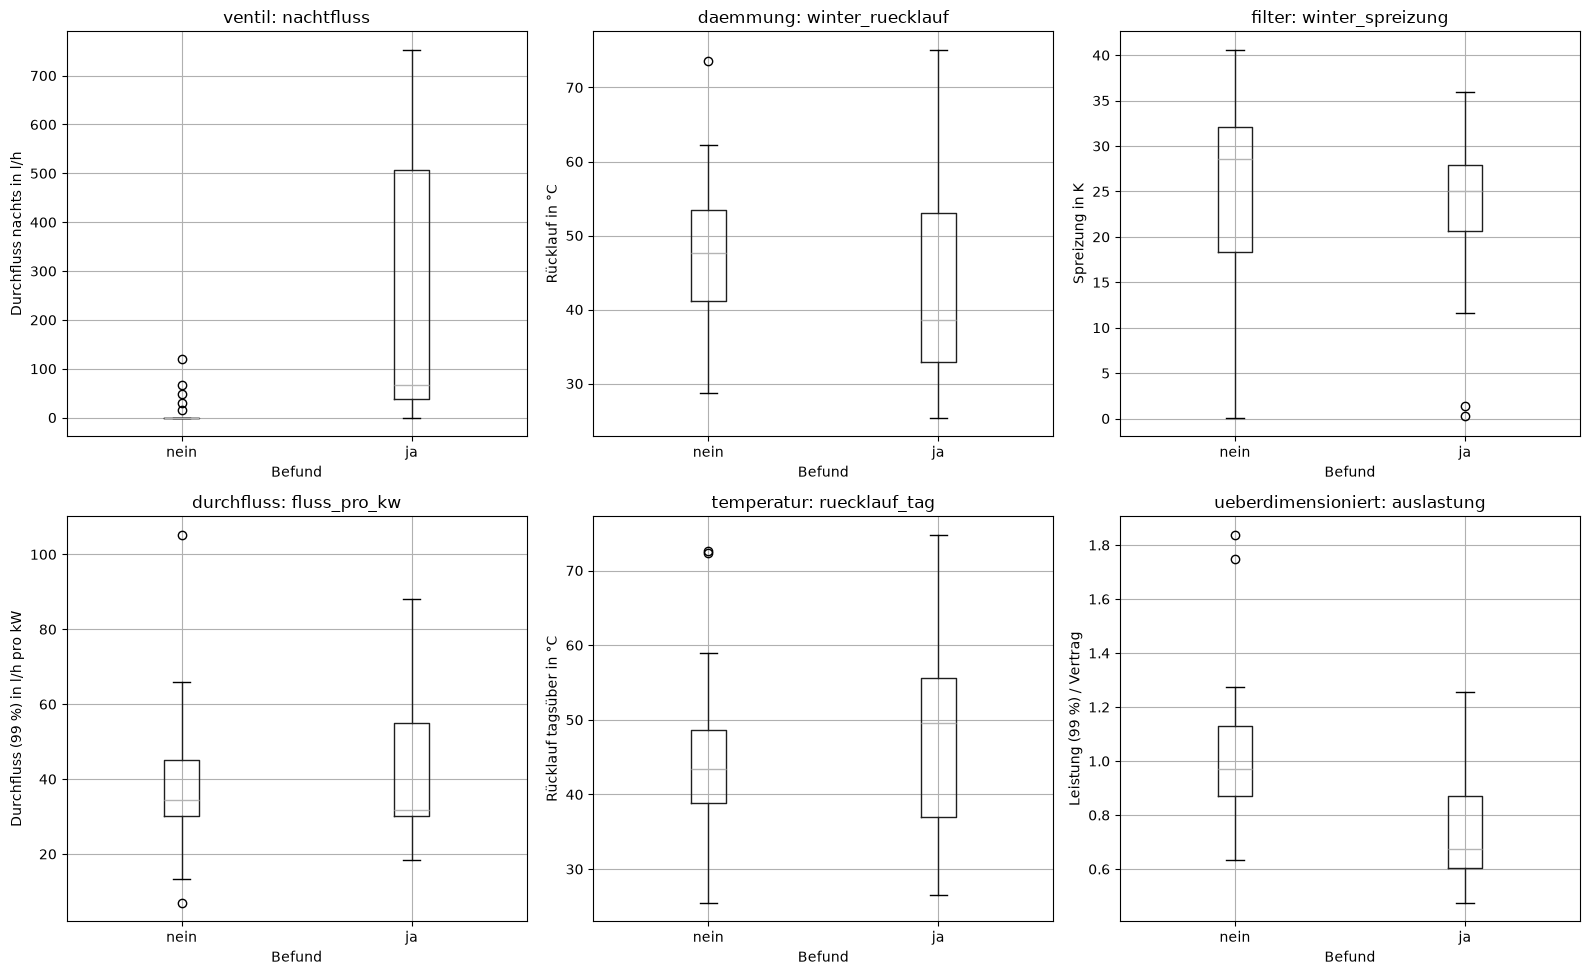

In [62]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (b, k) in zip(axes.flat, plan.items()):
    tabelle.dropna(subset=[k, b]).boxplot(column=k, by=b, ax=ax)
    ax.set_title(f"{b}: {k}")
    ax.set_xlabel("Befund")
    ax.set_xticklabels(["nein", "ja"])
    ax.set_ylabel(einheit[k])

fig.suptitle("")
fig.tight_layout()

In [63]:
fig.savefig(BILDER / "27_messlatte_boxplots.png", bbox_inches="tight")

- **Ventil:** Fast alle Stationen ohne Befund haben nachts 0 l/h. Die Kästen liegen weit auseinander.
- **Überdimensioniert:** Die Kästen überlappen sich kaum.
- **Dämmung und Temperatur:** Die Mitte ist verschoben, die Kästen überlappen sich aber stark.
- **Filter und Durchfluss:** Die Kästen liegen fast übereinander.

### 9.3 AUC statt Trefferquote

- Eine Grenze („ab 50 l/h ist das Ventil verdächtig“) ist immer ein Kompromiss zwischen gefundenen Fällen und Fehlalarmen.
- Die **AUC** bewertet eine Kennzahl über alle Grenzen zugleich: Sie ist die Wahrscheinlichkeit, dass von einem Paar (eine Station mit, eine ohne Befund) die mit Befund den auffälligeren Wert hat. 0,5 ist Raten, 1 ist perfekt.
- **Warum nicht Accuracy oder F1?** Beim Ventil haben 20 % der Stationen einen Befund. Wer immer „kein Befund“ sagt, liegt zu 80 % richtig und findet nichts. Accuracy und F1 hängen außerdem an einer gewählten Grenze und an der Basisrate. Die AUC hängt an keinem von beiden und ist deshalb zwischen Fehlerarten mit 9 und 36 Fällen vergleichbar. Für den Betrieb zählt später zusätzlich die Precision an einer festen Grenze: Wie viele Verdachtsfälle waren echt?

In [64]:
from sklearn.metrics import roc_auc_score

In [65]:
richtung = {"ventil": 1, "daemmung": -1, "filter": 1, "durchfluss": 1, "temperatur": 1, "ueberdimensioniert": -1}

for b, k in plan.items():
    tb = tabelle.dropna(subset=[k, b])
    auc = roc_auc_score(tb[b].astype(int), richtung[b] * tb[k])
    print(f"{b:20s} {k:18s} AUC {auc:.2f}   ({int(tb[b].sum())} Fälle von {len(tb)})")

ventil               nachtfluss         AUC 0.88   (11 Fälle von 53)
daemmung             winter_ruecklauf   AUC 0.64   (22 Fälle von 54)
filter               winter_spreizung   AUC 0.36   (25 Fälle von 54)
durchfluss           fluss_pro_kw       AUC 0.50   (19 Fälle von 54)
temperatur           ruecklauf_tag      AUC 0.60   (34 Fälle von 54)
ueberdimensioniert   auslastung         AUC 0.78   (9 Fälle von 35)


- **Ventil 0,88 und Überdimensionierung 0,78:** deutlich besser als Raten.
- **Dämmung 0,64 und Temperatur 0,60:** etwas besser als Raten.
- **Durchfluss 0,50:** Raten.
- **Filter 0,36:** unter 0,5, also eher andersherum als vermutet. Die Richtung wird trotzdem nicht umgedreht, sonst wäre sie nach dem Ergebnis gewählt (9.8).

### 9.4 Mehrere Kennzahlen kombinieren: logistische Regression

- Für die schwachen Fehlerarten liegt es nahe, mehrere Kennzahlen zu kombinieren. Das macht eine logistische Regression: Sie lernt für jede Kennzahl ein Gewicht.
- Vorher ein Test, was passiert, wenn man ein gelerntes Modell auf denselben Stationen prüft, auf denen es gelernt hat. Dafür reine Zufallszahlen statt Kennzahlen:

In [66]:
t = tabelle.dropna(subset=["winter_ruecklauf"])

In [67]:
import numpy as np
from sklearn.linear_model import LogisticRegression

np.random.seed(4)  #damit die Zufallszahlen bei jedem Ausführen gleich sind

In [68]:
zufall = pd.DataFrame(np.random.normal(size=(len(t), 10)))
modell = LogisticRegression()
modell.fit(zufall, t["daemmung"])
roc_auc_score(t["daemmung"], modell.predict_proba(zufall)[:, 1])

0.7528409090909091

- Zufallszahlen schaffen auf denselben Stationen eine AUC von 0,75, mehr als der echte Rücklauf (0,64). Das Modell hat sich nur gemerkt, welche Station welchen Befund hat (Überanpassung).
- Ehrlich ist nur eine Prüfung auf Stationen, die das Modell beim Lernen nicht gesehen hat. Bei rund 50 Stationen geht das mit **Leave-one-out**: Jede Station wird von einem Modell vorhergesagt, das ohne sie gelernt hat.

In [69]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict

In [70]:
vorhersage = cross_val_predict(LogisticRegression(), zufall, t["daemmung"], cv=LeaveOneOut(), method="predict_proba")[:,1]
roc_auc_score(t["daemmung"], vorhersage)

0.49005681818181823

- Mit Leave-one-out liegen die Zufallszahlen bei 0,49, also bei Raten. So soll eine ehrliche Prüfung aussehen.
- Jetzt mit echten Kennzahlen, erst mit Nachtdurchfluss und Winter-Rücklauf zusammen. `StandardScaler` bringt beide auf dieselbe Skala, damit das Gewicht nicht an der Einheit hängt.

In [71]:
merkmale= ["nachtfluss", "winter_ruecklauf"]
t= tabelle.dropna(subset=merkmale)

In [72]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [73]:
modell = make_pipeline(StandardScaler(), LogisticRegression())
vorhersage = cross_val_predict(modell, t[merkmale], t["daemmung"], cv=LeaveOneOut(), method="predict_proba")[:,1]
roc_auc_score(t["daemmung"], vorhersage)

0.6700879765395894

In [74]:
vorhersage = cross_val_predict(modell, t[merkmale], t["ventil"], cv=LeaveOneOut(), method="predict_proba")[:, 1]
roc_auc_score(t["ventil"], vorhersage)

0.841991341991342

- Dämmung 0,67 (Rücklauf allein 0,64), Ventil 0,84 (Nachtdurchfluss allein 0,88). Beim Ventil hilft die zweite Kennzahl nicht.
- Jetzt für alle Befunde mit allen fünf Kennzahlen, die es für fast alle Stationen gibt. Die `auslastung` bleibt draußen, weil sie nur 35 Stationen hat.

In [75]:
merkmale_alle = ["nachtfluss", "winter_ruecklauf", "winter_spreizung", "fluss_pro_kw", "ruecklauf_tag"]
t5 = tabelle.dropna(subset=merkmale_alle)
len(t5)

53

In [76]:
for b in ["ventil", "daemmung", "filter", "durchfluss", "temperatur"]:
    vorhersage = cross_val_predict(modell, t5[merkmale_alle], t5[b], cv=LeaveOneOut(), method="predict_proba")[:, 1]
    print(f"{b:12s} logistische Regression, Leave-one-out: AUC {roc_auc_score(t5[b], vorhersage):.2f}")

ventil       logistische Regression, Leave-one-out: AUC 0.77
daemmung     logistische Regression, Leave-one-out: AUC 0.64


filter       logistische Regression, Leave-one-out: AUC 0.54
durchfluss   logistische Regression, Leave-one-out: AUC 0.36


temperatur   logistische Regression, Leave-one-out: AUC 0.36


- Mit fünf Kennzahlen wird es nirgends besser als mit der passenden einzelnen: Ventil 0,77 statt 0,88, Dämmung 0,64.
- Bei Filter, Durchfluss und Temperatur findet das Modell nichts. Werte unter 0,5 heißen hier Raten, warum sie sogar darunter fallen, zeigt der Zufallstest in 9.7.
- Bei rund 50 Stationen und so wenigen Fällen muss das Modell zu viele Gewichte lernen. Die einfache Kennzahl bleibt die Messlatte.

### 9.5 Wie sicher ist eine AUC bei 11 Fällen?

- Mit anderen Stationen käme jedes Mal eine etwas andere AUC heraus. Wie groß dieser Zufall ist, schätzt der **Bootstrap**: 1000-mal die Stationen mit Zurücklegen ziehen und jedes Mal die AUC rechnen. Die mittleren 95 % der Werte sind das Intervall.
- Gezogen werden ganze Stationen, nicht Tage oder Stunden. Die Station ist die unabhängige Einheit: Ihre Tage hängen eng zusammen, und das Label gilt für die Station.

In [77]:
ergebnisse = []
for b, k in plan.items():
    tb = tabelle.dropna(subset=[k, b])
    y = tb[b].astype(int)
    auc = roc_auc_score(y, richtung[b] * tb[k])
    aucs = []
    for i in range(1000):
        s = tb.sample(len(tb), replace=True)
        aucs.append(roc_auc_score(s[b].astype(int), richtung[b] * s[k]))
    ergebnisse.append({"befund": b, "kennzahl": k, "faelle": y.sum(), "stationen": len(tb), "auc": auc,
                       "unten": np.percentile(aucs, 2.5), "oben": np.percentile(aucs, 97.5)})

In [78]:
ergebnisse = pd.DataFrame(ergebnisse)
ergebnisse.round(2)

,befund,kennzahl,faelle,stationen,auc,unten,oben
0,ventil,nachtfluss,11,53,0.88,0.73,0.99
1,daemmung,winter_ruecklauf,22,54,0.64,0.45,0.81
2,filter,winter_spreizung,25,54,0.36,0.20,0.51
3,durchfluss,fluss_pro_kw,19,54,0.50,0.33,0.66
4,temperatur,ruecklauf_tag,34,54,0.60,0.45,0.75
5,ueberdimensioniert,auslastung,9,35,0.78,0.53,0.98


| Befund | AUC | 95-%-Intervall | Lesart |
|---|---|---|---|
| Ventil | 0,88 | 0,73 bis 0,99 | klar über Raten |
| Überdimensioniert | 0,78 | 0,53 bis 0,98 | über Raten, sehr breit (9 Fälle) |
| Dämmung | 0,64 | 0,45 bis 0,81 | 0,5 liegt noch drin |
| Temperatur | 0,60 | 0,45 bis 0,75 | 0,5 liegt noch drin |
| Durchfluss | 0,50 | 0,33 bis 0,66 | Raten |
| Filter | 0,36 | 0,20 bis 0,51 | eher Gegenrichtung |

- Bei 11 Ventilfällen ist das Intervall rund ±0,13 breit. Unterschiede zwischen Modellen unter etwa 0,1 sind bei diesen Fallzahlen nicht zu sehen. Das gilt für alle folgenden Notebooks.

### 9.6 Straßen auslassen

- Stationen in derselben Straße hängen am selben Strang und wurden meist vom selben Techniker begangen. Liegt die Nachbarstation im Training, könnte ein Modell die Straße wiedererkennen statt den Befund.
- Deshalb eine zweite Prüfung, die ganze Straßen auslässt (`LeaveOneGroupOut`). Fällt die AUC dabei stark, hat das Modell von der Straße profitiert.

In [79]:
from sklearn.model_selection import LeaveOneGroupOut

In [80]:
for b in ["ventil", "daemmung", "filter", "durchfluss", "temperatur"]:
    v1 = cross_val_predict(modell, t5[merkmale_alle], t5[b], cv=LeaveOneOut(), method="predict_proba")[:, 1]
    v2 = cross_val_predict(modell, t5[merkmale_alle], t5[b], cv=LeaveOneGroupOut(), groups=t5["strasse_gruppe"], method="predict_proba")[:, 1]
    print(f"{b:12s} Leave-one-out: {roc_auc_score(t5[b], v1):.2f}   Straßen auslassen: {roc_auc_score(t5[b], v2):.2f}")

ventil       Leave-one-out: 0.77   Straßen auslassen: 0.80


daemmung     Leave-one-out: 0.64   Straßen auslassen: 0.66


filter       Leave-one-out: 0.54   Straßen auslassen: 0.55


durchfluss   Leave-one-out: 0.36   Straßen auslassen: 0.31


temperatur   Leave-one-out: 0.36   Straßen auslassen: 0.41


- Beim Ventil und bei der Dämmung ändert sich fast nichts (0,77 zu 0,80 und 0,64 zu 0,66). Die Straße spielt dort keine Rolle.
- Bei Filter, Durchfluss und Temperatur findet das Modell ohnehin nichts, die Werte schwanken nur.
- Die späteren Prüfungen lassen ganze Stationen aus (Notebook 27 bis 29 und 35), Notebook 29 zusätzlich ganze Straßen.

### 9.7 Zufallstest

- Labels durchmischen, sodass kein Befund mehr zu seiner Station passt, und zählen, wie oft der Zufall mindestens die echte AUC erreicht. Das ist ein Permutationstest.
- Erst für die logistische Regression bei der Dämmung, dann für jede einfache Kennzahl.

In [81]:
zufalls_aucs = []
for k in range(200):
    gemischt = t["daemmung"].sample(frac=1).values
    v = cross_val_predict(modell, t[merkmale], gemischt, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    zufalls_aucs.append(roc_auc_score(gemischt, v))

In [82]:
(np.array(zufalls_aucs) >= 0.67).mean()

np.float64(0.03)

In [83]:
np.median(zufalls_aucs)

np.float64(0.3885630498533724)

- Die echte AUC von 0,67 bei der Dämmung erreicht der Zufall in 3 % der 200 Durchläufe. Das ist ein Signal, aber kein starkes.
- Im Median liegt der Zufall bei Leave-one-out unter 0,5 (0,39). Das ist eine Eigenheit von Leave-one-out bei wenigen Fällen: Lässt man eine Station mit Befund weg, hat der Lernteil etwas weniger Befunde, und das Modell schätzt genau diese Station etwas niedriger ein. Bei einer Station ohne Befund ist es umgekehrt. Unter reinem Zufall landen die Befunde dadurch systematisch weiter hinten. Deshalb vergleicht man mit gemischten Labels und nicht einfach mit 0,5.
- Für die einfachen Kennzahlen geht der Zufallstest schneller, weil nichts gelernt wird. Wie oft erreicht der Zufall mindestens die echte AUC?

In [84]:
zufall_anteil = []
for b, k in plan.items():
    tb = tabelle.dropna(subset=[k, b])
    echt = roc_auc_score(tb[b].astype(int), richtung[b] * tb[k])
    zufalls = []
    for i in range(1000):
        gemischt = tb[b].astype(int).sample(frac=1).values
        zufalls.append(roc_auc_score(gemischt, richtung[b] * tb[k]))
    zufall_anteil.append((np.array(zufalls) >= echt).mean())

ergebnisse["zufall_anteil"] = zufall_anteil
ergebnisse.round(3)

,befund,kennzahl,faelle,stationen,auc,unten,oben,zufall_anteil
0,ventil,nachtfluss,11,53,0.878,0.734,0.992,0.000
1,daemmung,winter_ruecklauf,22,54,0.636,0.448,0.808,0.047
2,filter,winter_spreizung,25,54,0.356,0.203,0.514,0.966
3,durchfluss,fluss_pro_kw,19,54,0.504,0.329,0.664,0.491
4,temperatur,ruecklauf_tag,34,54,0.600,0.448,0.750,0.110
5,ueberdimensioniert,auslastung,9,35,0.778,0.530,0.982,0.008


- **Ventil** 0 % und **Überdimensionierung** 0,8 %: Der Zufall schafft das praktisch nie.
- **Dämmung** 4,7 %: Signal, aber knapp.
- **Temperatur** 11 %: In jedem neunten Durchlauf ist der Zufall genauso gut. Das reicht nicht.
- **Durchfluss** 49 % und **Filter** 97 %: kein Signal in die vermutete Richtung.

### 9.8 Die Messlatte

| Befund | Fälle | Kennzahl | AUC | 95-%-Intervall | Zufall mind. so gut | erkennbar? |
|---|---|---|---|---|---|---|
| Ventil | 11 von 53 | Nachtdurchfluss Sommer | 0,88 | 0,73 bis 0,99 | 0 % | ja |
| Überdimensioniert | 9 von 35 | Auslastung zum alten Vertrag | 0,78 | 0,53 bis 0,98 | 0,8 % | ja, wenige Fälle |
| Dämmung | 22 von 54 | Winter-Rücklauf (niedriger) | 0,64 | 0,45 bis 0,81 | 4,7 % | schwach |
| Temperatur | 34 von 54 | Rücklauf tagsüber | 0,60 | 0,45 bis 0,75 | 11 % | nein |
| Durchfluss | 19 von 54 | Durchfluss je kW | 0,50 | 0,33 bis 0,66 | 49 % | nein |
| Filter | 25 von 54 | Spreizung im Winter (höher) | 0,36 | 0,20 bis 0,51 | 97 % | nein, Vermutung falsch |

- **Warum die Kennzahlen vorher feststanden:** Hätte man je Befund zehn Kennzahlen probiert und die beste genommen, wäre deren AUC zu gut, weil die Auswahl die Antworten schon kennt. Will man doch auswählen, muss die Auswahl in jedem Durchgang nur auf den Lernstationen passieren (verschachtelte Kreuzvalidierung). So machen es Notebook 29 und 35.
- **Was jedes Modell schlagen muss:** beim Ventil 0,88, bei der Überdimensionierung 0,78, bei der Dämmung 0,64.
- **Wo Lernen helfen könnte:** bei der Dämmung, wo eine einzelne Kennzahl schwach ist. Dafür braucht es Merkmale, die mehr vom Verhalten einer Station erfassen, als eine Handvoll Kennzahlen. Das ist die Idee des LSTM in Notebook 27.

## 10 Ergebnis speichern

- Schreibt die drei Dateien für die Notebooks 26 bis 29.

In [85]:
stunden[["zaehler", "timestamp", *KANAELE]].to_parquet(PROCESSED / "modell_stunden.parquet", index=False)
kz.to_csv(PROCESSED / "modell_kennzahlen.csv")
labels.to_csv(PROCESSED / "modell_labels.csv")
for name in ("modell_stunden.parquet", "modell_kennzahlen.csv", "modell_labels.csv"):
    print(f"{name:26s} {(PROCESSED / name).stat().st_size / 1e6:6.1f} MB")

modell_stunden.parquet       18.6 MB
modell_kennzahlen.csv         0.0 MB
modell_labels.csv             0.0 MB


- Alle drei Dateien liegen in `data/processed/` und damit nicht im Repo.
- `modell_labels.csv` enthält keine Adressen, nur Zählernummer, Datum, Labels und die Straßennummer.

## Zusammenfassung & Bewertung

**Ergebnis**
- `modell_stunden.parquet`: 2,1 Mio. Stundenzeilen von 93 Zählern, mit Außentemperatur. Gebraucht in Notebook 27 und 28.
- `modell_kennzahlen.csv`: 14 Kennzahlen je Zähler (91 Zähler), nur aus Daten vor der Begehung. Gebraucht in Notebook 26, 27 und 29.
- `modell_labels.csv`: 6 Labels je begangenem Zähler (56), Datum, Straßennummer. Gebraucht in Notebook 26 bis 29.
- Fehlerbilder: Nur das Ventil ist in den Stundenwerten deutlich sichtbar, als Durchfluss in Sommernächten (9 von 11 Ventilfällen mit Durchfluss, ohne Befund 12 %) und als verkehrte Kennlinie. Dämmung und Filter sieht man an keiner Beispielstation.
- Messlatte je Fehlerart mit einer vorher festgelegten Kennzahl: Ventil AUC 0,88 [0,73; 0,99], Überdimensionierung 0,78 [0,53; 0,98], Dämmung 0,64 [0,45; 0,81]. Temperatur, Durchfluss und Filter liegen bei Raten.

**Belastbar**
- Dieselbe Datenbasis wie in Notebook 00: dieselben 93 bereinigten Zählerreihen, nichts neu gefiltert.
- Saubere zeitliche Trennung: Keine Kennzahl enthält Messungen nach der ersten Begehung eines Zählers.
- Ehrliche Prüfung der Messlatte: Richtung vorher festgelegt, Leave-one-out, ganze Straßen ausgelassen, Bootstrap über Stationen und Zufallstest. Eine Regression auf Zufallszahlen erreicht in der Lernmenge 0,75, mit Leave-one-out nur Raten.

**Schwach**
- Wenige Fälle: 11 Ventilfälle und 9 verkleinerte Verträge. Das 95-%-Intervall der AUC ist rund ±0,13 breit.
- Die Gegenbeispiele sind meist leere Kästchen. Bei Filter, Durchfluss und Dämmung steht nur 4- bis 8-mal ein ausdrückliches „nein“. „Leer ist nein“ kann die Labels verwässern.
- Temperatur ist bei zwei Dritteln gesetzt. Das zeigt eher, dass der Monteur fast überall den Sollwert gesenkt hat, als einen Fehler der Station.
- Der Anschlusswert in `Nodes_Edges.ods` ist teilweise schon der Stand nach der Begehung. Für die Überdimensionierung taugt er nicht als Bezug; dafür gibt es `auslastung_vertrag`.